# Phase 21 — Global MedFiLM Reference
### Four-domain task-conditioned global segmentation · full reviewer evidence

| Item | Value |
|---|---|
| Phase | 21 (Stage B) |
| Canonical folder | `notebooks/phasewise/phase_21_global_medfilm/` |
| Model | **ONE** shared four-domain task-conditioned Global MedFiLM |
| Task conditioning | FiLM `F_hat = (1 + gamma(t)) * F + beta(t)` at 5 sites |
| Shared output | ONE 1x1 head -> single foreground logit (no dataset-specific head) |
| Protocol | inherited EXACTLY from `reports/audits/phase20_shared_global_baseline_protocol.json` |
| Manifest | `manifests/phase4_v3` (TRAIN 5832 / VAL 808) |
| Selection rule | `phase20_macro_domain_mean_dice_v1` (frozen) |
| Cohorts read | TRAIN and VAL only |
| TEST | **CLOSED** — 0 image reads, 0 mask reads, 0 inference, 0 visualizations |
| Canonical VAL inference runs | exactly **1** |
| Logical training runs | exactly **1** (no architecture sweep, no hyperparameter sweep) |
| Terminal state | `PHASE21_GLOBAL_MEDFILM_REFERENCE_COMPLETE__PHASE22_ELIGIBLE_NOT_STARTED` |

**Scope guard.** Phase 21 is a **GLOBAL reference only**. It is **NOT** the final
RA-MedFiLM-Seg++ model. It contains NO ROI proposal, NO localizer, NO regional refiner,
NO high-resolution crop branch, NO global-regional fusion, NO benefit predictor, NO
counterfactual refinement gain, NO resource/budget router, NO adaptive conditional
computation, NO compression/pruning/quantization/distillation, NO architecture search,
and NO TEST evaluation.

**Interpretation guard.** There is **no architecture-matched control** (no identical plain
model trained under this Phase-21 run). The only permitted phrasing is
*"Global MedFiLM achieved X compared with baseline Y"*. Claiming *"FiLM caused +X"* is
**forbidden**. Where a paired CI overlaps zero, the models are **not separable**.

## 1. Environment and deterministic setup

In [1]:
import sys, json, hashlib, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path(r"D:/Softfors/jup")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image

from src.analysis import phase21_figures as F

EXP = "phase21_global_medfilm_fourdomain_seed42_clean_v3"
AUD, TAB = ROOT / "reports/audits", ROOT / "reports/tables"
FIG = ROOT / "reports/figures/phase21_global_medfilm"

def load(name):
    p = AUD / name
    return json.loads(p.read_text(encoding="utf-8")) if p.exists() else {}

def sha(p):
    p = Path(p)
    return hashlib.sha256(p.read_bytes()).hexdigest() if p.exists() else None

def sty(df, uid, fmt=None, **kw):
    """Deterministic Styler (fixed uuid => SHA-stable notebook output)."""
    fmt = {**(fmt or {}), **kw}
    return df.style.format(fmt).set_uuid(uid)

print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.4.6 | pandas 3.0.5


## 2. Governance and TEST lock

In [2]:
from src.utils.test_lock import verify_test_lock
verify_test_lock(str(ROOT))

FREEZE = load("phase21_final_freeze.json")
# The final freeze is written AFTER the notebook in the canonical pipeline order.
# When the freeze is absent (e.g. a pre-freeze notebook build), fall back to the
# same static interpretation guard so the notebook stays buildable and does NOT
# weaken the guard; once the freeze exists it is authoritative.
INTERP_FALLBACK = {
    "permitted": "Global MedFiLM achieved X compared with baseline Y.",
    "forbidden": "FiLM caused +X.",
    "reason": ("No architecture-matched control exists (no identical plain model trained "
               "under the Phase-21 run), so the difference cannot be causally attributed to FiLM."),
}
FREEZE.setdefault("interpretation", INTERP_FALLBACK)
gov = FREEZE.get("governance", {})
display(sty(pd.DataFrame([
    {"check": "TEST image reads", "value": gov.get("test_locks", {}).get("test_image_reads")},
    {"check": "TEST mask reads", "value": gov.get("test_locks", {}).get("test_mask_reads")},
    {"check": "TEST inference", "value": gov.get("test_locks", {}).get("test_inference")},
    {"check": "TEST visualizations", "value": gov.get("test_locks", {}).get("test_visualization")},
    {"check": "TEST reads observed (all artifacts)", "value": gov.get("test_reads_total_observed")},
    {"check": "FiLM used", "value": gov.get("film_used")},
    {"check": "Task conditioning used", "value": gov.get("task_conditioning_used")},
    {"check": "Forbidden components present", "value": gov.get("forbidden_components_present")},
]), "p21_gov", value="{!s}"))
print("TEST lock verified against manifests/test.csv sha256.")

,check,value
0,TEST image reads,0
1,TEST mask reads,0
2,TEST inference,0
3,TEST visualizations,0
4,TEST reads observed (all artifacts),0
5,FiLM used,True
6,Task conditioning used,True
7,Forbidden components present,[]


TEST lock verified against manifests/test.csv sha256.


## 3. Data contract and populations

In [3]:
EG = load("phase21_entry_gate.json")
display(sty(pd.DataFrame([
    {"item": "manifest_version", "value": EG.get("manifest_version")},
    {"item": "TRAIN population", "value": EG.get("train_population")},
    {"item": "VAL population", "value": EG.get("val_population")},
    {"item": "Task IDs", "value": json.dumps(EG.get("task_ids"))},
    {"item": "Entry-gate verdict", "value": EG.get("verdict")},
    {"item": "Entry-gate checks passed", "value": f"{EG.get('n_passed')}/{EG.get('n_checks')}"},
]), "p21_data", value="{!s}"))

run = pd.read_csv(ROOT / "experiments" / EXP / "history.csv")
print(f"Training history rows: {len(run)}")

,item,value
0,manifest_version,phase4_v3
1,TRAIN population,5832
2,VAL population,808
3,Task IDs,"{""ISIC"": 0, ""BUSI"": 1, ""KVASIR"": 2, ""KUB"": 3}"
4,Entry-gate verdict,PHASE21_ENTRY_GATE_PASS
5,Entry-gate checks passed,15/15


Training history rows: 81


## 4. Task-ID registry and conditioning policy

In [4]:
PB = load("phase21_protocol_binding.json")
task = PB.get("inherited_values", {}).get("task_ids", {})
display(sty(pd.DataFrame([
    {"task_id": 0, "domain": "ISIC", "modality": "dermoscopy (RGB)", "role": "FiLM conditioning"},
    {"task_id": 1, "domain": "BUSI", "modality": "ultrasound (L)", "role": "FiLM conditioning"},
    {"task_id": 2, "domain": "KVASIR", "modality": "endoscopy (RGB)", "role": "FiLM conditioning"},
    {"task_id": 3, "domain": "KUB", "modality": "radiograph (L/RGB)", "role": "FiLM conditioning"},
]), "p21_tasks", value="{!s}"))
print("task_id is CONDITIONING_ALLOWED but is NEVER a channel, never concatenated to the image,")
print("and never selects a dataset-specific head. Kidney/Ureteric/Bladder and TINY/SMALL/")
print("MEDIUM/LARGE are NEVER model inputs.")

,task_id,domain,modality,role
0,0,ISIC,dermoscopy (RGB),FiLM conditioning
1,1,BUSI,ultrasound (L),FiLM conditioning
2,2,KVASIR,endoscopy (RGB),FiLM conditioning
3,3,KUB,radiograph (L/RGB),FiLM conditioning


task_id is CONDITIONING_ALLOWED but is NEVER a channel, never concatenated to the image,
and never selects a dataset-specific head. Kidney/Ureteric/Bladder and TINY/SMALL/
MEDIUM/LARGE are NEVER model inputs.


## 5. Protocol binding — Phase-20 inheritance

In [5]:
inv = PB.get("inherited_values", {})
rows = [{"field": k, "phase20": json.dumps(v["phase20_protocol_value"])[:60],
         "phase21": json.dumps(v["phase21_value"])[:60], "identical": v["identical"]}
        for k, v in inv.items()]
display(sty(pd.DataFrame(rows), "p21_proto"))
print("Inherited identical:", PB.get("n_inherited_identical"), "/", PB.get("n_inherited_checks"))
print("Unintentional differences:", PB.get("unintentional_differences"))
print("Verdict:", PB.get("verdict"))
display(sty(pd.DataFrame(PB.get("intentional_differences", []))[
    ["field", "class", "reason"]], "p21_intent"))

,field,phase20,phase21,identical
0,manifest_version,"""phase4_v3""","""phase4_v3""",True
1,task_ids,"{""ISIC"": 0, ""BUSI"": 1, ""KVASIR"": 2, ""KUB"": 3}","{""ISIC"": 0, ""BUSI"": 1, ""KVASIR"": 2, ""KUB"": 3}",True
2,train_total,5832,5832,True
3,val_total,808,808,True
4,input_channel_policy,"""RGB_3CH""","""RGB_3CH""",True
5,input_resolution,512,512,True
6,sampling_policy,"""phase20_domain_balanced_uniform_v1""","""phase20_domain_balanced_uniform_v1""",True
7,loss,"{""name"": ""bce_dice"", ""bce_weight"": 0.5, ""dice_weight"": 0.5,","{""name"": ""bce_dice"", ""bce_weight"": 0.5, ""dice_weight"": 0.5,",True
8,optimizer,"{""name"": ""AdamW"", ""learning_rate"": 0.0001, ""weight_decay"": 0","{""name"": ""AdamW"", ""learning_rate"": 0.0001, ""weight_decay"": 0",True
9,learning_rate,0.0001,0.0001,True


Inherited identical: 24 / 24
Unintentional differences: []
Verdict: PHASE21_PROTOCOL_BINDING_PASS


,field,class,reason
0,architecture,INTENTIONAL_ARCHITECTURAL,Phase 21 is the task-conditioned Global MedFiLM reference. The shared UNet++ architecture is replaced by the reconstructed historical GLOBAL MedFiLM (residual shared encoder-decoder + 5 FiLM sites + ONE shared head).
1,experiment_id,INTENTIONAL_IDENTITY,"New phase, new experiment identity and new isolated output directories."
2,model.input_channels_consumed,INTENTIONAL_NO_CHANGE_DOCUMENTED,No change: the Phase-20 RGB_3CH channel policy is inherited EXACTLY. Listed here only to record that the legacy MedFiLM's 3-channel encoder first stage required no adapter.
3,task_id_role,INTENTIONAL_ARCHITECTURAL,"The defining Phase-21 change: task_id is permitted as a CONDITIONING input only. It is never a channel, never concatenated to the image, never a separate head, and no mask-derived metadata enters the model."
4,output_isolation,INTENTIONAL_IDENTITY,Isolated output directories; no frozen artifact is overwritten.


## 6. Legacy MedFiLM architecture audit

In [6]:
LA = load("phase21_legacy_medfilm_architecture_audit.json")
display(sty(pd.DataFrame([
    {"item": "evidence status", "value": LA.get("evidence_status")},
    {"item": "historical result claimed as current", "value": LA.get("not_current_prospective_result") is False},
    {"item": "legacy model class", "value": LA.get("historical_class_names", {}).get("film_model")},
    {"item": "FiLM module class", "value": LA.get("historical_class_names", {}).get("film_module")},
    {"item": "FiLM equation", "value": LA.get("film_equation", {}).get("form")},
    {"item": "FiLM sites", "value": json.dumps(LA.get("film_insertion_locations", {}).get("order"))},
    {"item": "squeeze-excitation", "value": LA.get("topology_features", {}).get("squeeze_excitation")},
    {"item": "deep supervision", "value": LA.get("topology_features", {}).get("deep_supervision")},
    {"item": "legacy task count", "value": LA.get("four_domain_compatibility", {}).get("legacy_task_count")},
    {"item": "legacy hyperparameters adopted", "value": False},
]), "p21_legacy", value="{!s}"))

,item,value
0,evidence status,PRIOR_ENGINEERING_EXPERIMENTAL_EVIDENCE
1,historical result claimed as current,False
2,legacy model class,MedFiLMSharedEncoderMultiTaskSegmenter
3,FiLM module class,FeatureWiseLinearModulation
4,FiLM equation,F_hat = (1 + gamma(t)) * F + beta(t)
5,FiLM sites,"[""bridge"", ""decoder4"", ""decoder3"", ""decoder2"", ""decoder1""]"
6,squeeze-excitation,False
7,deep supervision,False
8,legacy task count,3
9,legacy hyperparameters adopted,False


## 7. Frozen architecture definition

In [7]:
AB = load("phase21_global_medfilm_architecture_binding.json")
spec = AB.get("component_specification", {})
display(sty(pd.DataFrame([
    {"item": "architecture_id", "value": AB.get("architecture_id")},
    {"item": "verdict", "value": AB.get("verdict")},
    {"item": "frozen before training", "value": AB.get("frozen_before_training")},
    {"item": "measured parameters", "value": AB.get("measured_parameter_count")},
    {"item": "one shared parameter set", "value": AB.get("one_shared_parameter_set")},
    {"item": "dataset-specific head", "value": AB.get("dataset_specific_head")},
    {"item": "output definition", "value": AB.get("output_definition")},
    {"item": "forbidden-module audit passed", "value": AB.get("forbidden_module_audit", {}).get("passed")},
]), "p21_arch", value="{!s}"))
display(sty(pd.DataFrame(
    [{"component": k, "present": v} for k, v in spec.get("present", {}).items()]
    + [{"component": k, "present": v} for k, v in spec.get("absent", {}).items()]), "p21_arch2"))

,item,value
0,architecture_id,global_medfilm_shared_residual_unet_film5_no_se_no_deep_supervision_v1
1,verdict,PHASE21_ARCHITECTURE_FROZEN
2,frozen before training,True
3,measured parameters,3523001
4,one shared parameter set,True
5,dataset-specific head,False
6,output definition,single shared 1x1 head -> 1 foreground logit
7,forbidden-module audit passed,True


,component,present
0,residual_connections,True
1,task_embedding,True
2,film_conditioning,True
3,shared_segmentation_network,True
4,four_domain_joint_training,True
5,roi_proposal,False
6,localizer,False
7,regional_refiner,False
8,high_resolution_crop_branch,False
9,global_regional_fusion,False


## 8. FiLM mechanism

In [8]:
tc = AB.get("component_specification", {}).get("task_conditioning", {})
display(sty(pd.DataFrame([{"property": k, "value": json.dumps(v) if not isinstance(v, str) else v}
                          for k, v in tc.items()]), "p21_film_spec"))
print("Identity at initialisation: the FiLM output projection is zero-initialised, so every")
print("site starts as F_hat = F exactly. Task conditioning is therefore LEARNED, not injected.")

,property,value
0,mechanism,FiLM (feature-wise linear modulation)
1,equation,F_hat = (1 + gamma(t)) * F + beta(t)
2,gamma,tanh(gamma_raw)
3,beta,tanh(beta_raw)
4,output_projection_init,zeros -> EXACT identity at initialisation
5,task_embedding,"nn.Embedding(task_count, 32)"
6,task_embedding_init,"normal_(mean=0.0, std=0.02)"
7,film_hidden_dim,64
8,sites,"[""bridge"", ""decoder4"", ""decoder3"", ""decoder2"", ""decoder1""]"
9,site_count,5


Identity at initialisation: the FiLM output projection is zero-initialised, so every
site starts as F_hat = F exactly. Task conditioning is therefore LEARNED, not injected.


## 9. Pre-execution checks

In [9]:
PE = load("phase21_pre_execution_check.json")
rows = [{"check": k, "passed": v["passed"], "detail": json.dumps(v["detail"])[:90]}
        for k, v in PE.get("checks", {}).items()]
display(sty(pd.DataFrame(rows), "p21_pec"))
print("Verdict:", PE.get("verdict"), "|", PE.get("n_passed"), "/", PE.get("n_checks"),
      "| training_may_start:", PE.get("training_may_start"))

,check,passed,detail
0,architecture_binding_present,True,"{""verdict"": ""PHASE21_ARCHITECTURE_FROZEN""}"
1,model_file_sha_matches_binding,True,"{""repo"": ""a04ff3e61b4d900ff47c2f390da4a999e73bd6047b28a19e41b05115e431d11f"", ""binding"": ""a"
2,parameter_count_matches_binding,True,"{""measured"": 3523001, ""binding"": 3523001}"
3,forward_shape,True,"{""out_shape"": [2, 1, 512, 512]}"
4,output_spatial_matches_input,True,"{""in"": [512, 512], ""out"": [512, 512]}"
5,single_output_channel,True,"{""out_channels"": 1}"
6,unknown_task_id_rejected,True,"{""attempted"": [0, 4], ""task_count"": 4}"
7,task_id_shape_enforced,True,"{""attempted"": ""[1] for batch 2""}"
8,all_four_task_ids_accepted,True,"{""task_ids"": [0, 1, 2, 3]}"
9,film_identity_at_init,True,"{""max_abs_output_diff_across_tasks"": 0.0, ""meaning"": ""zero-initialised FiLM output project"


Verdict: PHASE21_PRE_EXECUTION_CHECK_PASS | 27 / 27 | training_may_start: True


## 10. Training configuration (inherited protocol)

In [10]:
cfg = json.loads((ROOT / "experiments" / EXP / "config.json").read_text(encoding="utf-8"))
display(sty(pd.DataFrame([
    {"field": "loss", "value": json.dumps(cfg["loss"])},
    {"field": "optimizer", "value": json.dumps(cfg["optimizer"])},
    {"field": "scheduler", "value": json.dumps(cfg["scheduler"])},
    {"field": "batch_size", "value": cfg["training"]["batch_size"]},
    {"field": "eval_batch_size", "value": cfg["training"]["eval_batch_size"]},
    {"field": "amp", "value": cfg["training"]["amp"]},
    {"field": "seed", "value": cfg["training"]["seed"]},
    {"field": "max_epochs", "value": cfg["training"]["max_epochs"]},
    {"field": "early_stopping_patience", "value": cfg["training"]["early_stopping_patience"]},
    {"field": "sampling_policy", "value": cfg["training"]["sampling_policy"]},
    {"field": "checkpoint_metric", "value": cfg["training"]["checkpoint_metric"]},
    {"field": "input_channel_policy", "value": cfg["input_channel_policy"]},
    {"field": "input_resolution", "value": cfg["input_resolution"]},
]), "p21_cfg", value="{!s}"))

,field,value
0,loss,"{""name"": ""bce_dice"", ""bce_weight"": 0.5, ""dice_weight"": 0.5, ""dice_epsilon"": 1e-06}"
1,optimizer,"{""name"": ""AdamW"", ""learning_rate"": 0.0001, ""weight_decay"": 0.0001}"
2,scheduler,"{""name"": ""CosineAnnealingLR"", ""T_max"": 100, ""step"": ""per_epoch_after_train_and_val""}"
3,batch_size,4
4,eval_batch_size,8
5,amp,True
6,seed,42
7,max_epochs,100
8,early_stopping_patience,15
9,sampling_policy,phase20_domain_balanced_uniform_v1


## 11. Training run manifest

In [11]:
RM = json.loads((ROOT / "experiments" / EXP / "run_manifest.json").read_text(encoding="utf-8"))
display(sty(pd.DataFrame([
    {"item": "experiment_id", "value": RM["experiment_id"]},
    {"item": "architecture_id", "value": RM["architecture_id"]},
    {"item": "model params", "value": RM["model_params"]},
    {"item": "TRAIN total", "value": RM["dataset_populations"]["TRAIN_total"]},
    {"item": "VAL total", "value": RM["dataset_populations"]["VAL_total"]},
    {"item": "torch", "value": RM["environment"]["torch"]},
    {"item": "gpu", "value": RM["environment"]["gpu_name"]},
    {"item": "run started (UTC)", "value": RM["run_started_utc"]},
]), "p21_rm", value="{!s}"))
display(sty(pd.DataFrame([{"code": k, "sha256": v[:16] + "..."}
                          for k, v in RM["code_shas"].items()]), "p21_rm2"))

,item,value
0,experiment_id,phase21_global_medfilm_fourdomain_seed42_clean_v3
1,architecture_id,global_medfilm_shared_residual_unet_film5_no_se_no_deep_supervision_v1
2,model params,3523001
3,TRAIN total,5832
4,VAL total,808
5,torch,2.6.0+cu124
6,gpu,NVIDIA GeForce RTX 3060 Ti
7,run started (UTC),2026-09-28T16:21:11


,code,sha256
0,scripts/training/train_phase21_global_medfilm.py,ec17641b8e6e680a...
1,scripts/training/phase21_common.py,7591a8a44715ad29...
2,src/models/film/global_medfilm.py,a04ff3e61b4d900f...
3,src/models/film/__init__.py,3df73eaa34394291...
4,src/models/factory.py,f97f97a5632675ae...


## 12. Training curves — loss

*Figure — Training and validation loss*  
`reports/figures/phase21_global_medfilm/training/training_loss.png`

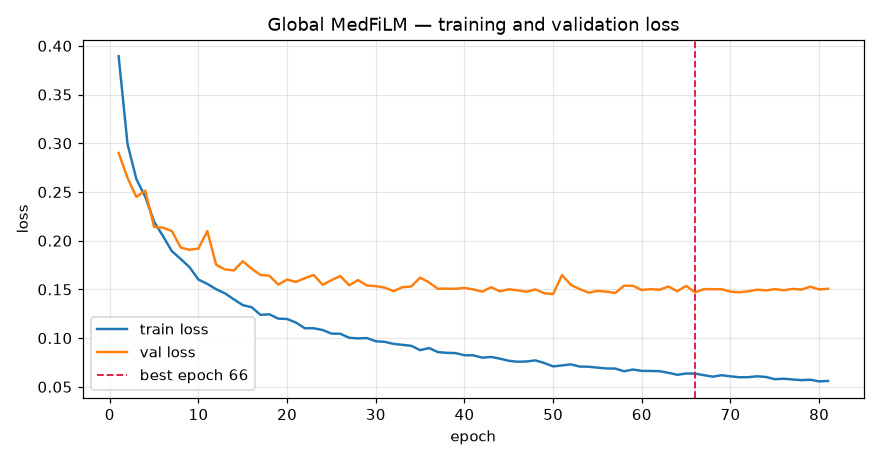

*Figure — Per-epoch wall time*  
`reports/figures/phase21_global_medfilm/training/training_epoch_time.png`

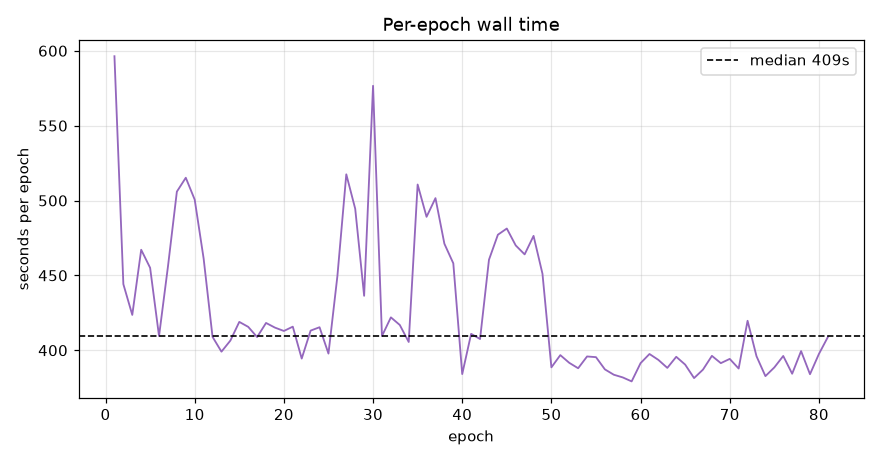

In [12]:
CACHE = F.build_all(progress=lambda *a, **k: None)
INV_OUT = F.write_inventories()

# Embedding-size policy (empirically calibrated from the corrupted package).
#
# MEASURED FACT: in the previous reviewer package the corrupted ``image/png``
# payloads were exactly the largest ones. Their base64 lengths were
# 1,346,139 / 1,270,209 / 701,719 characters, and all three came back with an
# ODD length (i.e. exactly one character lost) while still ending in a valid PNG
# ``IEND`` terminator. Corruption was probabilistic above ~7e5 chars: the
# 1,635,252 / 1,528,600 / 864,064-char payloads survived by luck.
#
# MEASURED SIZE GAP in the frozen inventory: the 8 multi-panel gallery figures
# are 544,836-1,635,252 base64 chars, while ALL 35 non-gallery figures are
# <= 85,876 chars. A single blanket cap would therefore silently DOWNSCALE the
# 35 small figures (which never needed it) and degrade reviewer figure quality.
#
# Policy: preserve FULL SOURCE RESOLUTION whenever the payload is inside the
# measured-safe envelope, and downscale only the oversized gallery panels.
FIG_EMBED_SAFE_B64 = 250_000         # safely above 85,876, far below 544,836
FIG_EMBED_MAX_PX = 1600              # never exceed the source panel width

def _bounded_png(path):
    """Return PNG bytes for `path` at full fidelity when it fits the safe envelope.

    Returns ``(data, (w, h))``. Figures whose base64 payload is already within
    ``FIG_EMBED_SAFE_B64`` are returned BYTE-IDENTICAL to the source file, so no
    reviewer-visible detail is lost. Only oversized payloads (the multi-panel
    galleries) are progressively downscaled until they fit.
    """
    import base64, io
    from PIL import Image as _PILImage

    raw = open(path, "rb").read()
    if len(base64.b64encode(raw)) <= FIG_EMBED_SAFE_B64:
        with _PILImage.open(io.BytesIO(raw)) as _im:
            return raw, (_im.width, _im.height)      # full source fidelity

    with _PILImage.open(path) as im:
        im = im.convert("RGB") if im.mode not in ("RGB", "L") else im.copy()
        scale = 1.0
        while True:
            w = max(1, int(round(im.width * scale)))
            h = max(1, int(round(im.height * scale)))
            if max(w, h) > FIG_EMBED_MAX_PX:
                scale *= 0.9
                continue
            buf = io.BytesIO()
            im.resize((w, h), _PILImage.LANCZOS).save(buf, format="PNG",
                                                      optimize=True)
            data = buf.getvalue()
            if len(base64.b64encode(data)) <= FIG_EMBED_SAFE_B64 or scale < 0.2:
                return data, (w, h)
            scale *= 0.85

def show_fig(fig_id, width=1050):
    """Embed one inventory figure EXACTLY ONCE, from the frozen inventory.

    The payload is embedded at FULL SOURCE RESOLUTION whenever it fits the
    measured-safe base64 envelope; only the oversized gallery panels are
    downscaled (see ``_bounded_png``). Identifier resolution is driven by
    ``phase21_figure_inventory.csv`` so a figure can never be silently skipped
    by a hardcoded list.
    """
    import base64 as _b64
    inv = F.figure_inventory()
    row = inv[inv["figure_id"] == fig_id]
    assert len(row) == 1, f"missing figure: {fig_id}"
    rel = str(row.iloc[0]["saved_path"])
    display(Markdown(f"*Figure — {row.iloc[0]['title']}*  \n`{rel}`"))
    p = ROOT / rel
    assert p.exists(), f"figure file absent on disk: {p}"
    data, (w, h) = _bounded_png(p)
    b64 = _b64.b64encode(data).decode("ascii")
    assert len(b64) % 4 == 0, f"base64 length not a multiple of 4 for {fig_id}"
    # NOTE: pass the base64 string through ``Image(data=...)`` only when it is a
    # list of chunks; a bare ``str`` is interpreted by IPython as a FILE PATH.
    # The robust route is to hand ``display`` the raw PNG bytes via Image(data=...)
    # with an explicit ``format='png'`` and ``embed=True``.
    display(Image(data=data, format="png", embed=True, width=min(width, w)))

def show_group(prefix, width=900):
    """Embed every inventory figure whose id starts with `prefix`."""
    ids = sorted(fid for fid in F.figure_inventory()["figure_id"]
                 if str(fid).startswith(prefix))
    print(f"{prefix}* : {len(ids)} figure(s) in the frozen inventory")
    for fid in ids:
        show_fig(fid, width=width)
    return ids

show_fig("p21_train_loss")
show_fig("p21_train_epoch_time")

## 13. Training curves — macro Dice and frozen selection

*Figure — Macro-domain VAL Dice with the frozen selection marker*  
`reports/figures/phase21_global_medfilm/training/training_macro_dice.png`

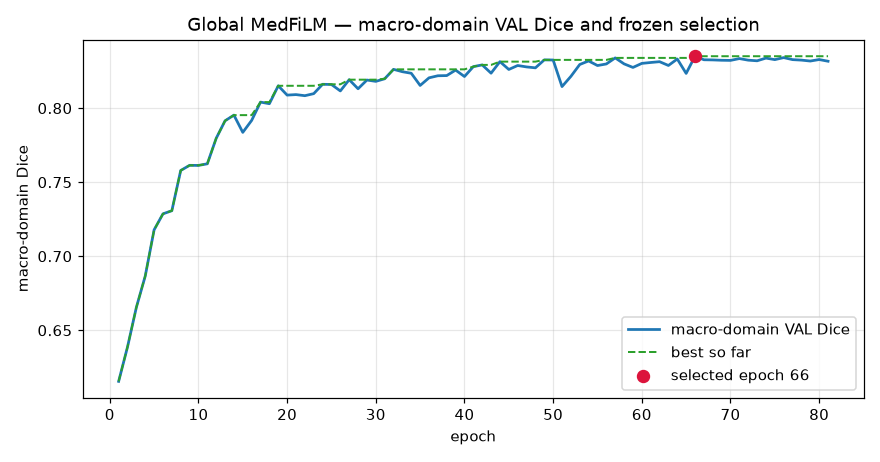

,item,value
0,best epoch (in-loop),66.0
1,best macro-domain Dice,0.8350791259413984
2,final epoch,81.0


In [13]:
show_fig("p21_train_macro")
best_ep = int(run.loc[run["macro_domain_dice"].idxmax(), "epoch"])
display(sty(pd.DataFrame([
    {"item": "best epoch (in-loop)", "value": best_ep},
    {"item": "best macro-domain Dice", "value": float(run["macro_domain_dice"].max())},
    {"item": "final epoch", "value": int(run["epoch"].iloc[-1])},
]), "p21_best", value="{!s}"))

## 14. Training curves — per-domain Dice

*Figure — Per-domain VAL Dice curves*  
`reports/figures/phase21_global_medfilm/training/training_per_domain_dice.png`

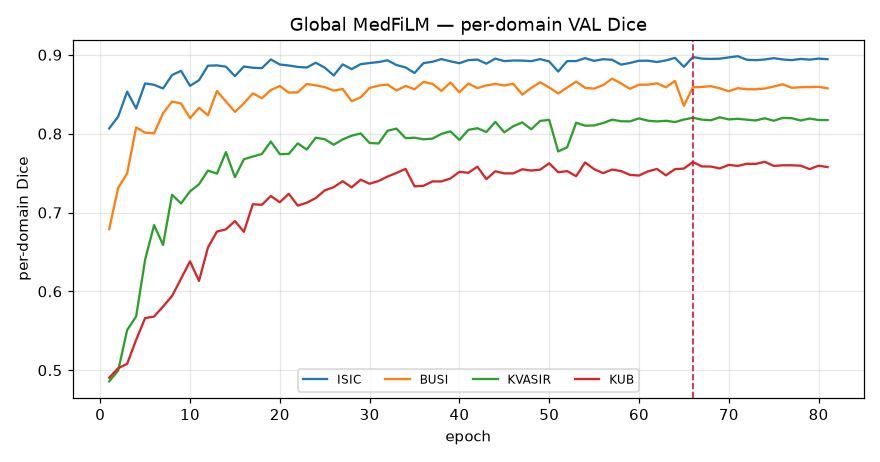

,epoch,train_loss,val_loss,macro_domain_dice,val_dice_ISIC,val_dice_BUSI,val_dice_KVASIR,val_dice_KUB
69,70,0.060797,0.147716,0.832262,0.896766,0.853808,0.818075,0.760398
70,71,0.059827,0.147018,0.833488,0.898240,0.857676,0.818902,0.759135
71,72,0.059916,0.148083,0.832418,0.893779,0.856347,0.817725,0.761823
72,73,0.060830,0.149679,0.831988,0.893219,0.856313,0.816804,0.761615
73,74,0.060143,0.148937,0.833808,0.894085,0.857255,0.819526,0.764368
74,75,0.057803,0.150284,0.832779,0.895808,0.859788,0.816374,0.759145
75,76,0.058343,0.149103,0.834150,0.894108,0.862633,0.819971,0.759887
76,77,0.057570,0.150547,0.832780,0.893316,0.858193,0.819661,0.759951
77,78,0.056881,0.149761,0.832451,0.894791,0.858881,0.816726,0.759407
78,79,0.057313,0.152856,0.831825,0.893892,0.859176,0.819183,0.755050


In [14]:
show_fig("p21_train_domain_dice")
cols = ["epoch", "train_loss", "val_loss", "macro_domain_dice"] + [f"val_dice_{d}" for d in ["ISIC","BUSI","KVASIR","KUB"]]
display(sty(run[cols].tail(12), "p21_tail"))

## 15. Learning-rate schedule and early stopping

*Figure — Learning-rate schedule*  
`reports/figures/phase21_global_medfilm/training/training_lr_schedule.png`

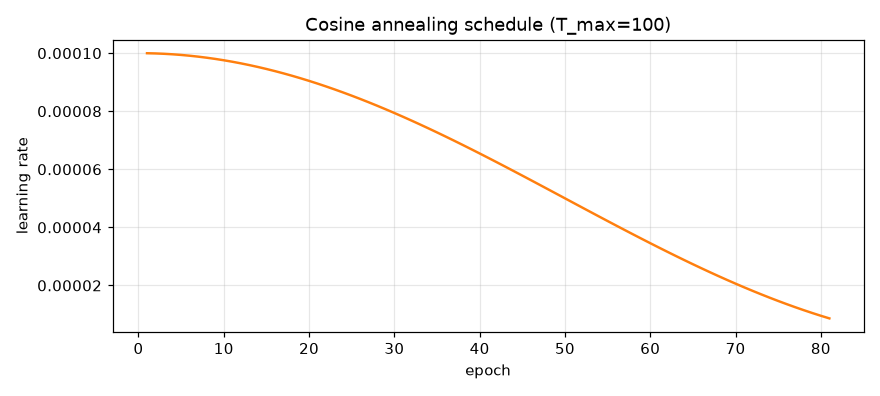

*Figure — Early-stopping counter*  
`reports/figures/phase21_global_medfilm/training/training_early_stop.png`

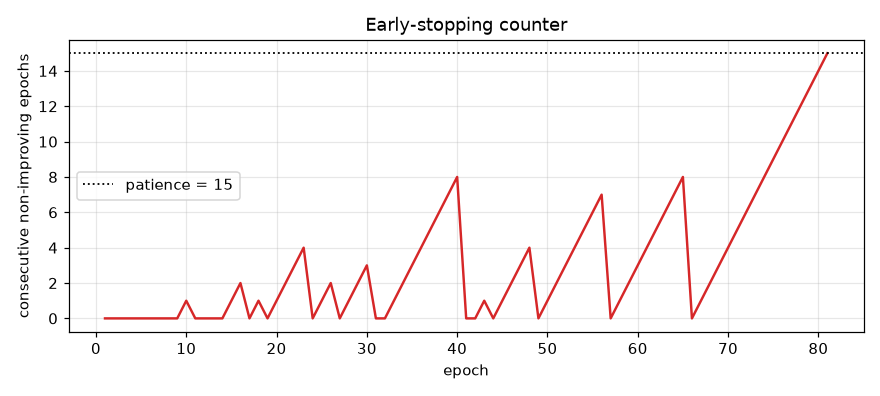

In [15]:
show_fig("p21_train_lr")
show_fig("p21_train_earlystop")

## 16. Checkpoint selection replay (disk only)

In [16]:
RP = json.loads((ROOT / "experiments" / EXP /
                 "phase21_checkpoint_selection_replay.json").read_text(encoding="utf-8"))
display(sty(pd.DataFrame([
    {"item": "selection rule", "value": RP["selection_rule_id"]},
    {"item": "replayed best epoch", "value": RP["replayed_best_epoch"]},
    {"item": "replayed macro Dice", "value": RP["replayed_best_macro_domain_dice"]},
    {"item": "training best epoch", "value": RP["training_best_epoch"]},
    {"item": "matches training", "value": RP["replay_matches_training"]},
    {"item": "verdict", "value": RP["verdict"]},
]), "p21_replay", value="{!s}"))

,item,value
0,selection rule,phase20_macro_domain_mean_dice_v1
1,replayed best epoch,66
2,replayed macro Dice,0.8350791259413984
3,training best epoch,66
4,matches training,True
5,verdict,PHASE21_CHECKPOINT_SELECTION_REPLAY_PASS


## 17. Training closure

In [17]:
CL = json.loads((ROOT / "experiments" / EXP /
                 "phase21_training_closure.json").read_text(encoding="utf-8"))
display(sty(pd.DataFrame([
    {"item": "best epoch", "value": CL["best_epoch"]},
    {"item": "best macro-domain Dice", "value": CL["best_macro_domain_dice"]},
    {"item": "best val loss", "value": CL["best_val_loss"]},
    {"item": "final epoch", "value": CL["final_epoch"]},
    {"item": "stop reason", "value": CL["stop_reason"]},
    {"item": "resume count", "value": CL["resume_count"]},
    {"item": "independent duplicate runs", "value": CL["independent_duplicate_runs"]},
    {"item": "model params", "value": CL["model_params"]},
    {"item": "elapsed (h)", "value": round(CL["total_elapsed_seconds"]/3600, 2)},
    {"item": "checkpoint replay verdict", "value": CL["checkpoint_selection_replay_verdict"]},
]), "p21_closure", value="{!s}"))
display(sty(pd.DataFrame([{"domain": k, "dice_at_best": v}
                          for k, v in CL["per_domain_dice_at_best"].items()]), "p21_closure2"))

,item,value
0,best epoch,66
1,best macro-domain Dice,0.8350791259413984
2,best val loss,0.14694273973455524
3,final epoch,81
4,stop reason,EARLY_STOPPING_PATIENCE
5,resume count,1
6,independent duplicate runs,0
7,model params,3523001
8,elapsed (h),9.61
9,checkpoint replay verdict,PHASE21_CHECKPOINT_SELECTION_REPLAY_PASS


,domain,dice_at_best
0,ISIC,0.897189
1,BUSI,0.858823
2,KVASIR,0.820246
3,KUB,0.764059


## 18. Canonical VAL evaluation

In [18]:
VE = load("phase21_val_evaluation.json")
PM = load("phase21_prediction_manifest.json")
display(sty(pd.DataFrame([
    {"item": "canonical VAL inference runs", "value": VE["canonical_val_inference_runs"]},
    {"item": "samples expected", "value": VE["samples_expected"]},
    {"item": "samples evaluated", "value": VE["samples_evaluated"]},
    {"item": "threshold", "value": VE["threshold"]},
    {"item": "no TTA", "value": VE["no_tta"]},
    {"item": "no threshold tuning", "value": VE["no_threshold_tuning"]},
    {"item": "no morphology", "value": VE["no_morphology"]},
    {"item": "prob maps persisted", "value": VE["prob_maps_persisted"]},
    {"item": "checkpoint SHA (16)", "value": VE["checkpoint_sha256"][:16] + "..."},
]), "p21_val", value="{!s}"))
display(sty(pd.DataFrame([{"domain": k, "n": v}
                          for k, v in PM["per_domain_counts"].items()]), "p21_val2"))

,item,value
0,canonical VAL inference runs,1
1,samples expected,808
2,samples evaluated,808
3,threshold,0.5
4,no TTA,True
5,no threshold tuning,True
6,no morphology,True
7,prob maps persisted,808
8,checkpoint SHA (16),286689fdd5c63ad7...


,domain,n
0,BUSI,84
1,ISIC,357
2,KUB,280
3,KVASIR,87


## 19. Per-domain performance

In [19]:
DP = pd.read_csv(TAB / "phase21_global_medfilm_domain_performance.csv")
cols = ["row_type", "dataset", "n", "dice", "dice_ci_low", "dice_ci_high", "iou",
        "precision", "recall", "specificity", "balanced_accuracy", "mcc",
        "hd95", "assd", "surface_dice", "roc_auc", "pr_auc", "brier", "ece", "mce"]
display(sty(DP[cols], "p21_dp"))

,row_type,dataset,n,dice,dice_ci_low,dice_ci_high,iou,precision,recall,specificity,balanced_accuracy,mcc,hd95,assd,surface_dice,roc_auc,pr_auc,brier,ece,mce
0,DOMAIN,ISIC,357,0.897189,0.884029,0.909009,0.829819,0.914264,0.906878,0.978246,0.942562,0.882482,26.005116,9.224066,0.366412,0.991545,0.967491,0.026933,0.019945,0.218185
1,DOMAIN,BUSI,84,0.858823,0.836749,0.878818,0.763646,0.860091,0.880625,0.994022,0.937324,0.858506,31.949904,7.463158,0.398489,0.981968,0.922584,0.010593,0.009552,0.324020
2,DOMAIN,KVASIR,87,0.820247,0.775232,0.862746,0.735523,0.862652,0.826200,0.977960,0.902080,0.806817,67.047850,17.705459,0.422680,0.956134,0.870565,0.041578,0.037590,0.264626
3,DOMAIN,KUB,280,0.764058,0.739344,0.787823,0.650358,0.760812,0.803676,0.966002,0.884839,0.744683,51.880826,20.256604,0.345519,0.987865,0.934772,0.032935,0.017740,0.192475
4,MACRO_DOMAIN,MACRO_DOMAIN,808,0.835079,0.787749,0.878006,0.744837,0.849455,0.854345,0.979058,0.916701,0.823122,44.220924,13.662322,0.383275,nan,nan,nan,nan,nan
5,POOLED_DESCRIPTIVE,POOLED_DESCRIPTIVE,808,0.878424,nan,nan,0.783206,0.876372,0.880486,0.978181,0.929334,0.857012,nan,nan,nan,nan,nan,nan,nan,nan


## 20. Macro-domain result and 95% CI

In [20]:
AN = load("phase21_analysis.json")
gm = AN["global_medfilm"]
display(sty(pd.DataFrame([
    {"item": "macro-domain VAL Dice", "value": gm["macro_domain_dice"]},
    {"item": "95% CI low", "value": gm["macro_domain_dice_ci_low"]},
    {"item": "95% CI high", "value": gm["macro_domain_dice_ci_high"]},
    {"item": "macro-domain IoU", "value": gm["macro_domain_iou"]},
    {"item": "pooled Dice (descriptive)", "value": gm["pooled_dice_descriptive"]},
    {"item": "rank among six models", "value": f"{gm['rank_among_six']}/6"},
]), "p21_macro", value="{!s}"))
display(sty(pd.DataFrame([{"domain": k, "dice": v}
                          for k, v in gm["per_domain_dice"].items()]), "p21_macro2"))

,item,value
0,macro-domain VAL Dice,0.8350794169575282
1,95% CI low,0.787749404492504
2,95% CI high,0.8780060341568547
3,macro-domain IoU,0.7448366561463977
4,pooled Dice (descriptive),0.8784243406054913
5,rank among six models,1/6


,domain,dice
0,ISIC,0.897189
1,BUSI,0.858823
2,KVASIR,0.820247
3,KUB,0.764058


## 21. Confusion matrices

*Figure — Confusion matrices per domain and pooled*  
`reports/figures/phase21_global_medfilm/comparison/confusion_matrices.png`

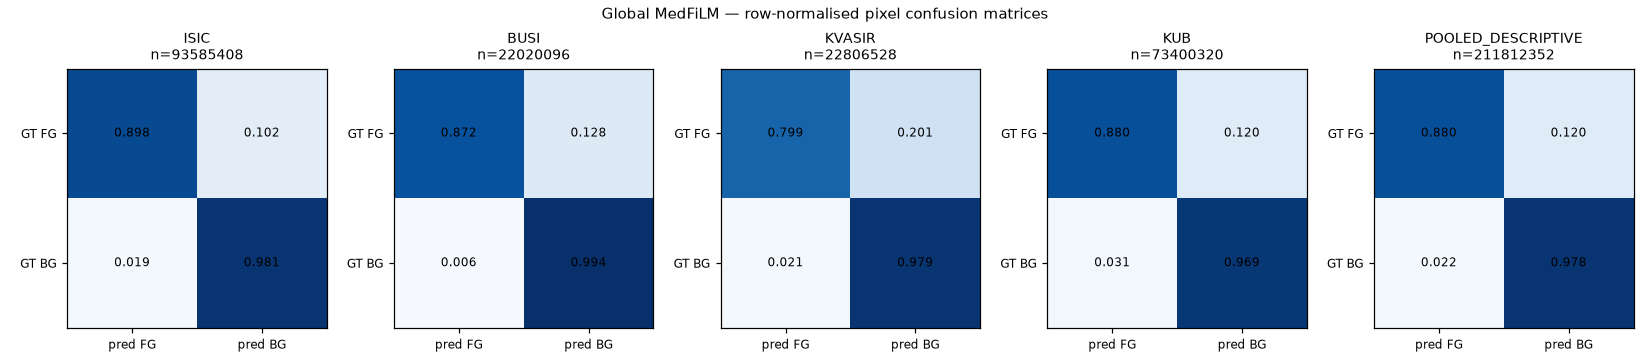

,scope,tp,tn,fp,fn,total,row_norm_gt_fg_tp,row_norm_gt_fg_fn,row_norm_gt_bg_fp,row_norm_gt_bg_tn
0,ISIC,14594127,75870368,1461448,1659465,93585408,0.897902,0.102098,0.018898,0.981102
1,BUSI,974946,20781547,120852,142751,22020096,0.872281,0.127719,0.005782,0.994218
2,KVASIR,2601722,19135612,414878,654316,22806528,0.799045,0.200955,0.021221,0.978779
3,KUB,9695481,60445054,1933866,1325919,73400320,0.879696,0.120304,0.031002,0.968998
4,POOLED_DESCRIPTIVE,27866276,176232581,3931044,3782451,211812352,0.880486,0.119514,0.021819,0.978181


In [21]:
show_fig("p21_confusion")
CM = pd.read_csv(TAB / "phase21_global_medfilm_confusion_matrices.csv")
display(sty(CM[["scope", "tp", "tn", "fp", "fn", "total", "row_norm_gt_fg_tp",
                "row_norm_gt_fg_fn", "row_norm_gt_bg_fp", "row_norm_gt_bg_tn"]], "p21_cm"))

## 22. Calibration and ranking metrics

*Figure — ROC-AUC and PR-AUC by domain*  
`reports/figures/phase21_global_medfilm/comparison/ranking_metrics.png`

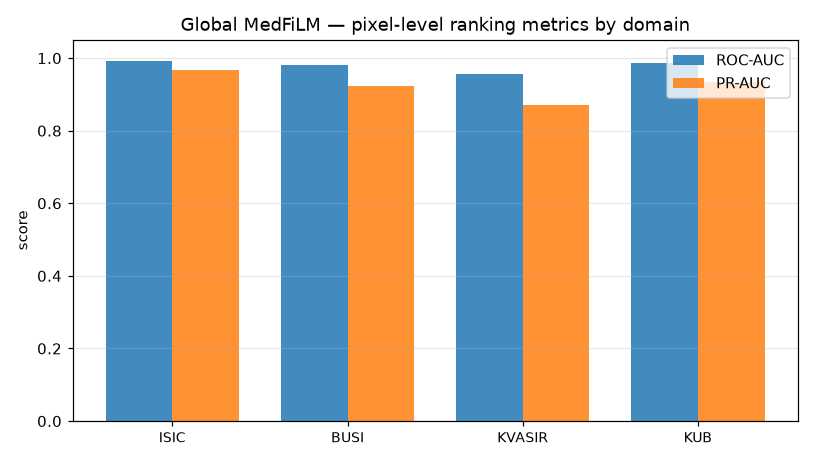

*Figure — Brier / ECE / MCE by domain*  
`reports/figures/phase21_global_medfilm/comparison/calibration_metrics.png`

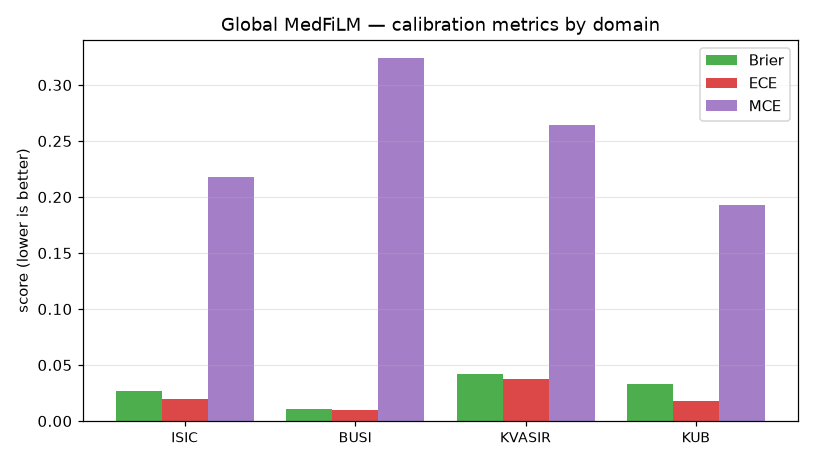

,dataset,n_images,n_pixels_subsampled,subsample_stride,brier,ece,mce,roc_auc,pr_auc_average_precision,prevalence
0,ISIC,357,5849088,4,0.026933,0.019945,0.218185,0.991545,0.967491,0.173638
1,BUSI,84,1376256,4,0.010593,0.009552,0.324020,0.981968,0.922584,0.050730
2,KVASIR,87,1425408,4,0.041578,0.037590,0.264626,0.956134,0.870565,0.142673
3,KUB,280,4587520,4,0.032935,0.017740,0.192475,0.987865,0.934772,0.150115


In [22]:
show_fig("p21_ranking")
show_fig("p21_calibration")
display(sty(pd.read_csv(TAB / "phase21_global_medfilm_calibration_ranking.csv"), "p21_cal"))

## 23. Six-model benchmark comparison

*Figure — Six-model macro-domain VAL Dice with bootstrap CI*  
`reports/figures/phase21_global_medfilm/comparison/six_model_macro_dice.png`

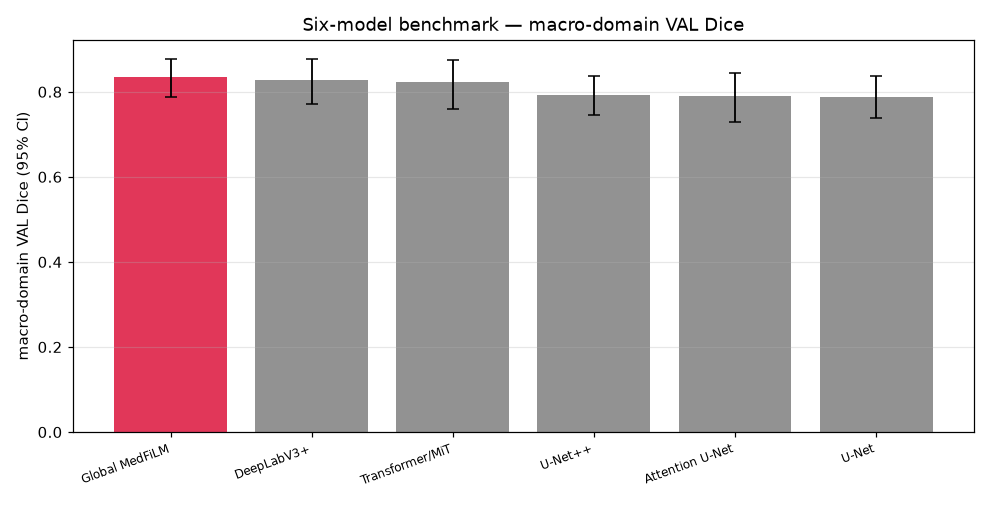

,model_key,display_name,phase,params,macro_domain_dice,macro_domain_dice_ci_low,macro_domain_dice_ci_high,dice_ISIC,dice_BUSI,dice_KVASIR,dice_KUB
0,global_medfilm,Global MedFiLM,21,nan,0.835079,0.787749,0.878006,0.897189,0.858823,0.820247,0.764058
1,deeplabv3plus,DeepLabV3+,20B,40347041.000000,0.827652,0.770725,0.876131,0.885345,0.866918,0.819686,0.738660
2,transformer_mit_unet,Transformer/MiT-style U-Net,20B,16347777.000000,0.822383,0.759882,0.875536,0.887090,0.863982,0.813277,0.725182
3,unetpp,U-Net++,20A,9159681.000000,0.792010,0.744572,0.838188,0.860074,0.816303,0.771001,0.720662
4,attention_unet,Attention U-Net,20B,7851285.000000,0.789037,0.728752,0.844685,0.861694,0.827675,0.770999,0.695778
5,unet,U-Net,20B,7763041.000000,0.787832,0.738143,0.837522,0.855274,0.819770,0.755196,0.721089


*Figure — Parameter count comparison*  
`reports/figures/phase21_global_medfilm/comparison/parameter_comparison.png`

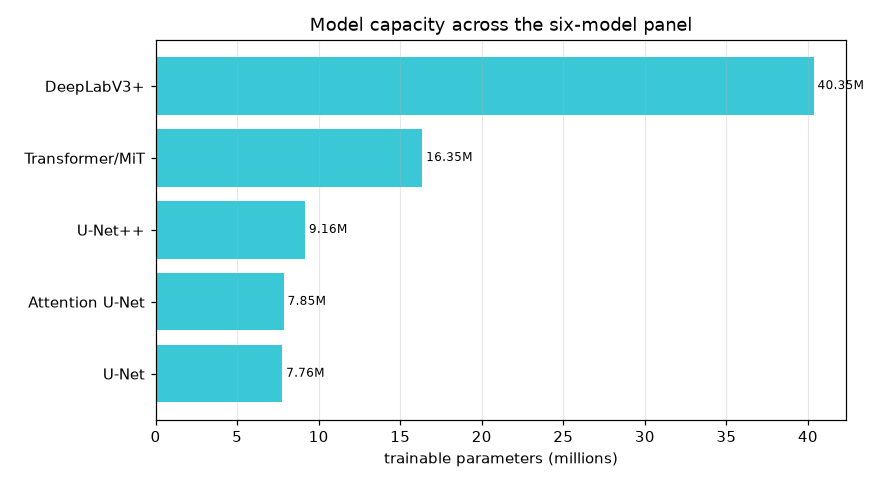

In [23]:
show_fig("p21_cmp_macro")
CMP = pd.read_csv(TAB / "phase21_six_model_comparison.csv")
display(sty(CMP[["model_key", "display_name", "phase", "params", "macro_domain_dice",
                 "macro_domain_dice_ci_low", "macro_domain_dice_ci_high",
                 "dice_ISIC", "dice_BUSI", "dice_KVASIR", "dice_KUB"]], "p21_cmp"))
show_fig("p21_cmp_params")

## 24. Per-domain matrix across six models

Every metric matrix present in the frozen figure inventory is embedded below. The
set is read from `phase21_figure_inventory.csv` rather than hardcoded, so a metric
cannot be silently omitted from the reviewer package again.

*Figure — Per-domain Dice matrix*  
`reports/figures/phase21_global_medfilm/comparison/six_model_per_domain_matrix.png`

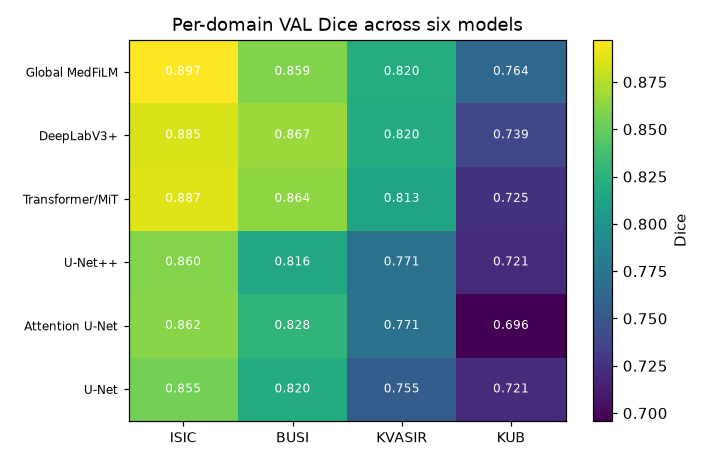

metric-matrix figures in the frozen inventory: 10


*Figure — assd matrix*  
`reports/figures/phase21_global_medfilm/comparison/metric_matrix_assd.png`

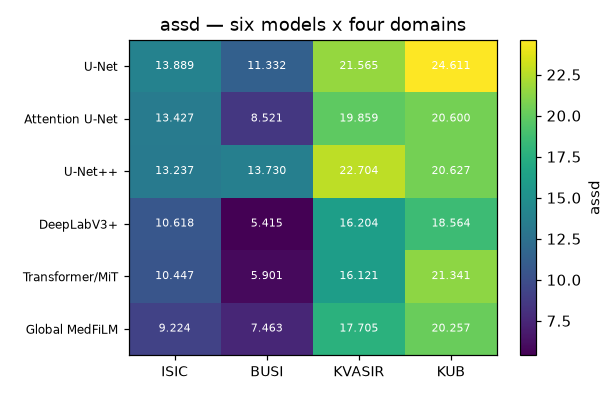

*Figure — balanced_accuracy matrix*  
`reports/figures/phase21_global_medfilm/comparison/metric_matrix_balanced_accuracy.png`

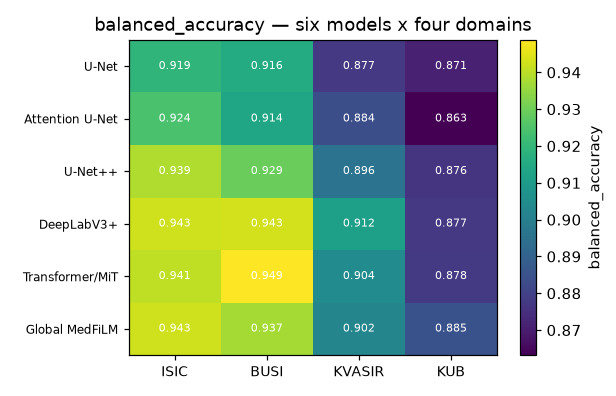

*Figure — dice matrix*  
`reports/figures/phase21_global_medfilm/comparison/metric_matrix_dice.png`

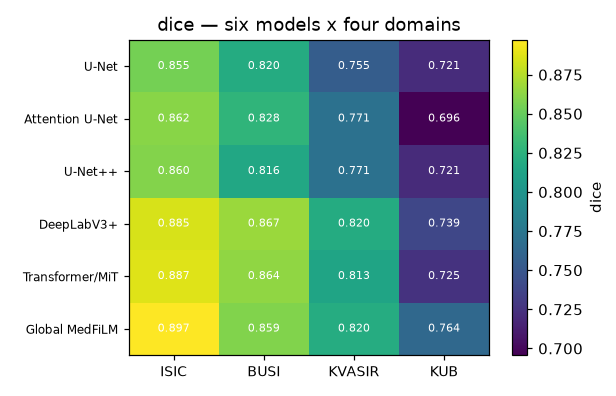

*Figure — hd95 matrix*  
`reports/figures/phase21_global_medfilm/comparison/metric_matrix_hd95.png`

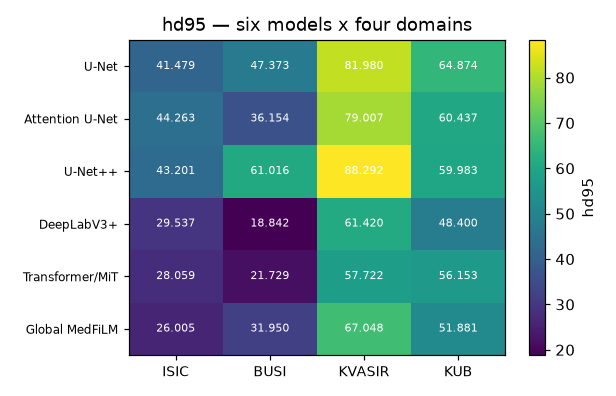

*Figure — iou matrix*  
`reports/figures/phase21_global_medfilm/comparison/metric_matrix_iou.png`

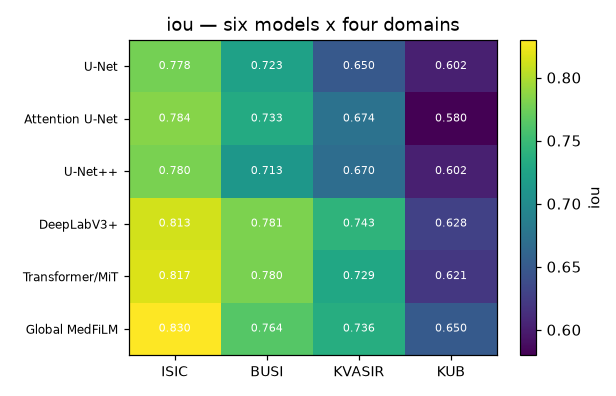

*Figure — mcc matrix*  
`reports/figures/phase21_global_medfilm/comparison/metric_matrix_mcc.png`

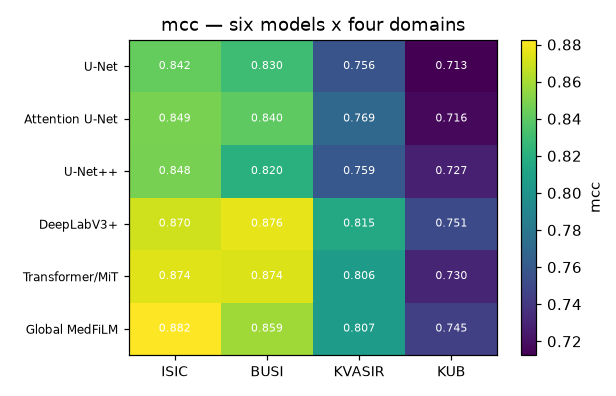

*Figure — precision matrix*  
`reports/figures/phase21_global_medfilm/comparison/metric_matrix_precision.png`

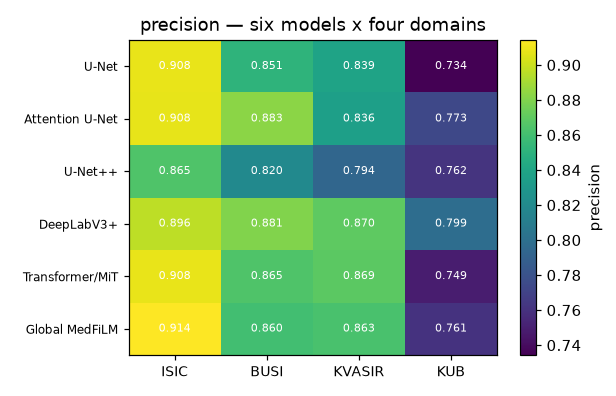

*Figure — recall matrix*  
`reports/figures/phase21_global_medfilm/comparison/metric_matrix_recall.png`

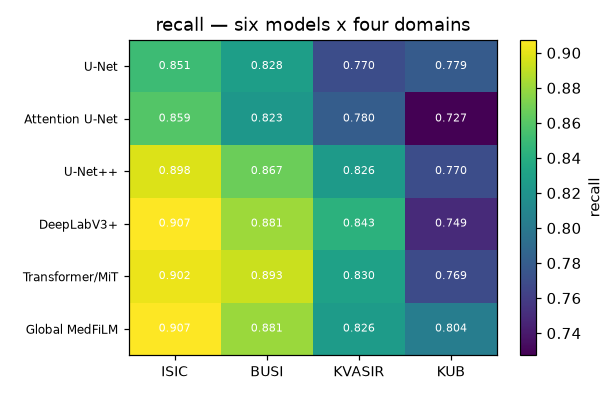

*Figure — specificity matrix*  
`reports/figures/phase21_global_medfilm/comparison/metric_matrix_specificity.png`

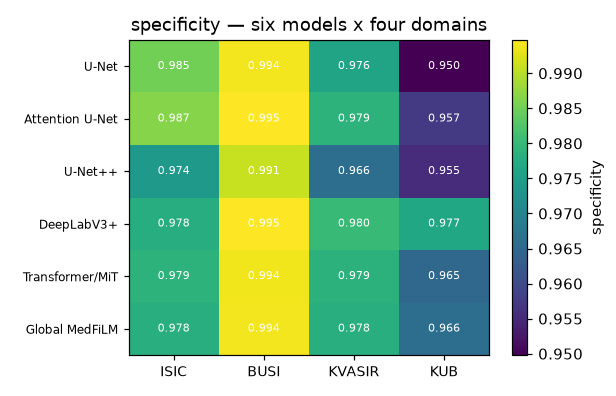

*Figure — surface_dice matrix*  
`reports/figures/phase21_global_medfilm/comparison/metric_matrix_surface_dice.png`

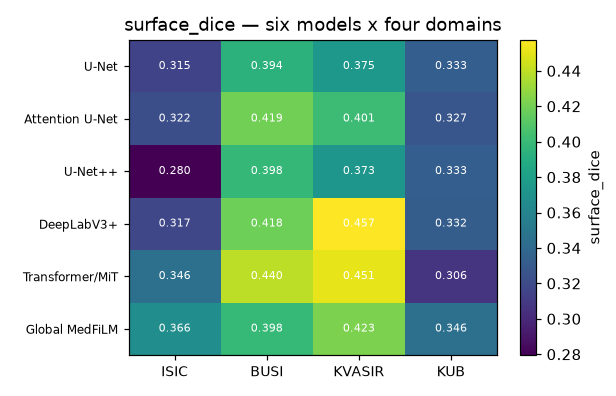

In [24]:
show_fig("p21_cmp_domain_matrix")
# Drive coverage from the FROZEN INVENTORY, not from a hardcoded list: the old
# five-item loop silently dropped specificity / mcc / balanced_accuracy / assd /
# surface_dice from the reviewer package.
_metric_ids = sorted(
    fid for fid in F.figure_inventory()["figure_id"]
    if str(fid).startswith("p21_metric_"))
print(f"metric-matrix figures in the frozen inventory: {len(_metric_ids)}")
for _fid in _metric_ids:
    show_fig(_fid, width=820)

## 25. Paired domain-stratified bootstrap vs the five frozen baselines

*Figure — Paired bootstrap difference forest plot*  
`reports/figures/phase21_global_medfilm/comparison/paired_bootstrap_forest.png`

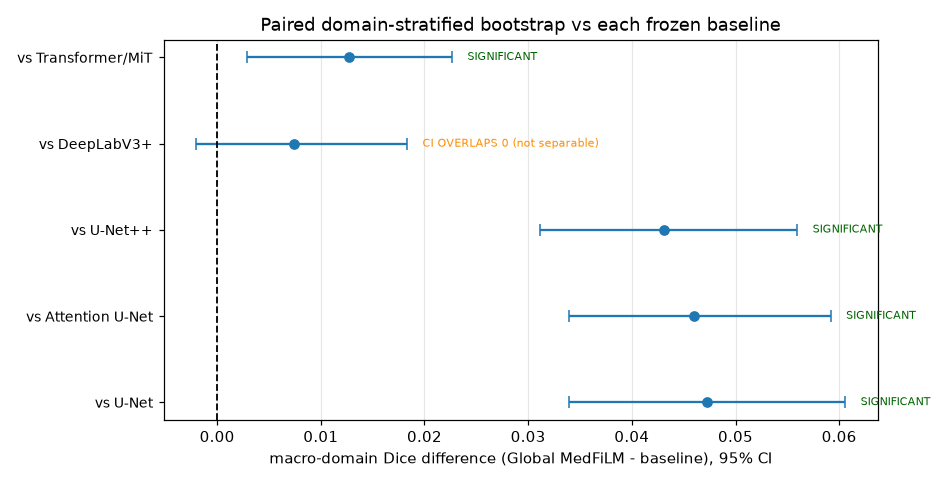

,model_b,observed_diff,diff_ci_low,diff_ci_high,ci_excludes_zero,p_value_two_sided,significant_at_0.05
0,unet,0.047247,0.033954,0.060571,True,0.000000,True
1,attention_unet,0.046043,0.033900,0.059171,True,0.000000,True
2,unetpp,0.043070,0.031098,0.055944,True,0.000000,True
3,deeplabv3plus,0.007427,-0.002042,0.018313,False,0.124000,False
4,transformer_mit_unet,0.012697,0.002860,0.022645,True,0.013000,True


n_boot: 2000 | seed: 42 | unit: domain_stratified_paired_image


In [25]:
show_fig("p21_cmp_paired")
PA = pd.read_csv(TAB / "phase21_paired_bootstrap_vs_baselines.csv")
display(sty(PA[["model_b", "observed_diff", "diff_ci_low", "diff_ci_high",
                "ci_excludes_zero", "p_value_two_sided", "significant_at_0.05"]], "p21_pa"))
PBJ = load("phase21_paired_bootstrap.json")
print("n_boot:", PBJ["n_boot"], "| seed:", PBJ["seed"], "| unit:", PBJ["resampling_unit"])

## 26. Statistical interpretation guard

In [26]:
sig = AN["paired_bootstrap"]["significant_vs_baselines"]
ns = AN["paired_bootstrap"]["non_significant_vs_baselines"]
print("PERMITTED :", FREEZE["interpretation"]["permitted"])
print("FORBIDDEN :", FREEZE["interpretation"]["forbidden"])
print("Reason    :", FREEZE["interpretation"]["reason"])
print()
print("Differences that are statistically separable (CI excludes 0):", sig)
print("Differences whose CI OVERLAPS zero (models NOT separable)     :", ns)
print()
print("No causal attribution to FiLM is made anywhere in this package.")

PERMITTED : Global MedFiLM achieved X compared with baseline Y.
FORBIDDEN : FiLM caused +X.
Reason    : No architecture-matched control exists (no identical plain model trained under the Phase-21 run), so the difference cannot be causally attributed to FiLM.

Differences that are statistically separable (CI excludes 0): ['unet', 'attention_unet', 'unetpp', 'transformer_mit_unet']
Differences whose CI OVERLAPS zero (models NOT separable)     : ['deeplabv3plus']

No causal attribution to FiLM is made anywhere in this package.


## 27. KUB subgroup analysis (REPORTING ONLY)

*Figure — KUB subgroup Dice*  
`reports/figures/phase21_global_medfilm/kub/kub_subgroup_dice.png`

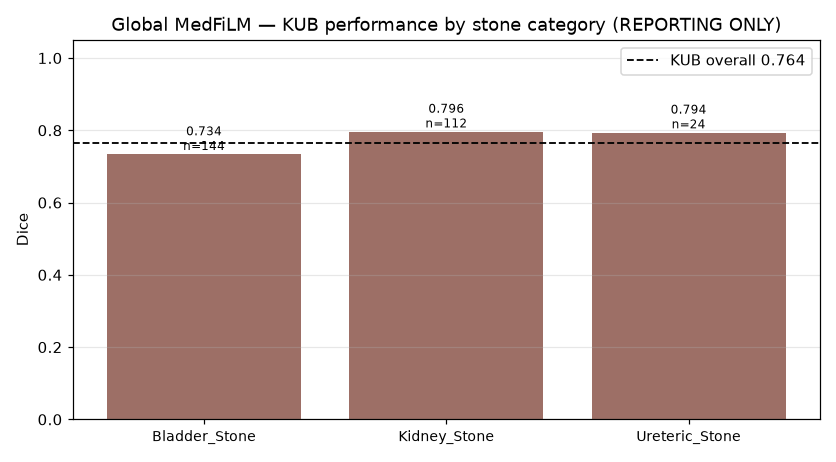

,scope,subgroup,n,dice,iou,precision,recall,hd95,empty_prediction_rate,role
0,KUB_ALL,KUB_ALL,280,0.764058,0.650358,0.760812,0.803676,51.880826,0.000000,REPORTING_ONLY
1,KUB_SUBGROUP,Bladder_Stone,144,0.733945,0.616313,0.712706,0.793832,51.864262,0.000000,REPORTING_ONLY
2,KUB_SUBGROUP,Kidney_Stone,112,0.796378,0.686368,0.823852,0.805037,51.859788,0.000000,REPORTING_ONLY
3,KUB_SUBGROUP,Ureteric_Stone,24,0.793914,0.686586,0.755258,0.856392,52.078386,0.000000,REPORTING_ONLY


Kidney/Ureteric/Bladder categories are REPORTING-ONLY and are NEVER model inputs.


In [27]:
show_fig("p21_kub_subgroup")
KS = pd.read_csv(TAB / "phase21_kub_subgroup_analysis.csv")
display(sty(KS, "p21_ks"))
print("Kidney/Ureteric/Bladder categories are REPORTING-ONLY and are NEVER model inputs.")

## 28. KUB size stratification (TINY preserved for Phase 22)

*Figure — KUB size-stratum Dice*  
`reports/figures/phase21_global_medfilm/kub/kub_size_strata_dice.png`

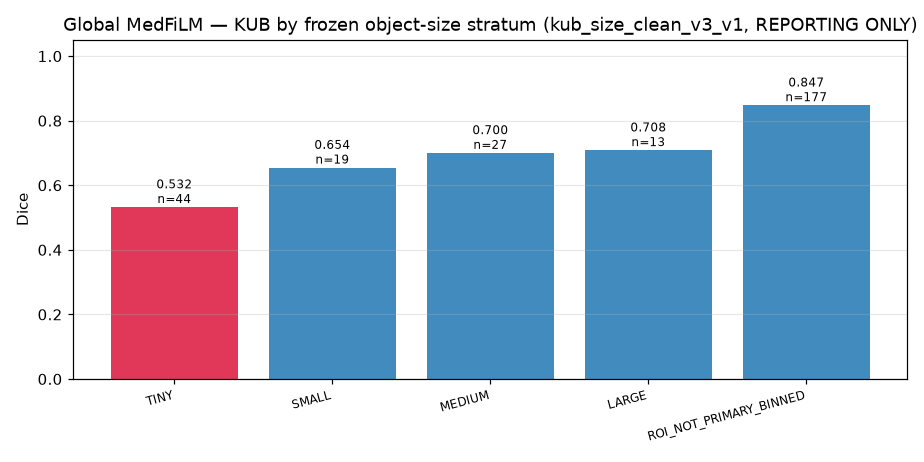

,stratum,n,dice,iou,median_component_ratio,taxonomy_id,role
0,TINY,44,0.532079,0.413734,0.000095,kub_size_clean_v3_v1,REPORTING_ONLY__DESCRIPTIVE
1,SMALL,19,0.654176,0.512595,0.000195,kub_size_clean_v3_v1,REPORTING_ONLY__DESCRIPTIVE
2,MEDIUM,27,0.699821,0.562175,0.000553,kub_size_clean_v3_v1,REPORTING_ONLY__DESCRIPTIVE
3,LARGE,13,0.708226,0.607751,0.001763,kub_size_clean_v3_v1,REPORTING_ONLY__DESCRIPTIVE
4,ROI_NOT_PRIMARY_BINNED,177,0.847420,0.740550,nan,kub_size_clean_v3_v1,REPORTING_ONLY__DESCRIPTIVE


Taxonomy: kub_size_clean_v3_v1 (FROZEN). TINY stratum is preserved as evidence and was
NOT optimised on.


In [28]:
show_fig("p21_kub_size")
KZ = pd.read_csv(TAB / "phase21_kub_size_stratification.csv")
display(sty(KZ, "p21_kz"))
print("Taxonomy: kub_size_clean_v3_v1 (FROZEN). TINY stratum is preserved as evidence and was")
print("NOT optimised on.")

## 29. Task-conditioning diagnostic

*Figure — Task-conditioning effect size*  
`reports/figures/phase21_global_medfilm/conditioning/conditioning_diagnostic.png`

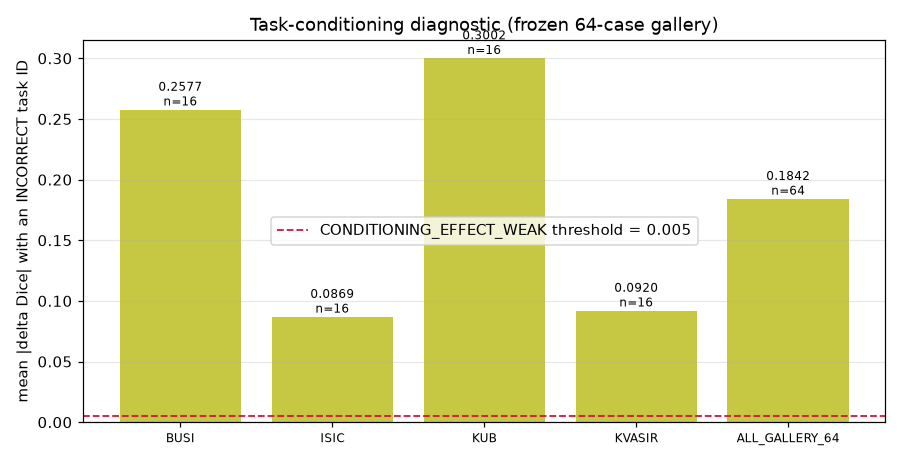

,item,value
0,scope,"frozen 64-case gallery (16 per domain), reused UNCHANGED"
1,n cases,64
2,mean |delta Dice| with wrong task,0.18419164050715645
3,max |delta Dice| with wrong task,0.9270517063993946
4,mean Dice with correct task,0.859145553979417
5,flag,CONDITIONING_EFFECT_PRESENT
6,flag rule,CONDITIONING_EFFECT_WEAK when mean|delta Dice| < 0.005


> A weak effect is a legitimate scientific finding about this reference model and is reported as-is. It is NOT evidence that task conditioning is useless in general, and a strong effect here would NOT by itself prove that FiLM caused the benchmark gap (no architecture-matched control exists).

,scope,n,mean_dice_correct_task,mean_abs_delta_dice_wrong_task,max_abs_delta_dice_wrong_task,mean_signed_delta_all_wrong,n_improved_by_wrong_task,n_degraded_by_wrong_task
0,BUSI,16,0.871077,0.257728,0.927052,nan,11,37
1,ISIC,16,0.907108,0.086906,0.739576,nan,15,33
2,KUB,16,0.782814,0.300157,0.829268,nan,5,42
3,KVASIR,16,0.875584,0.091975,0.723590,nan,11,37
4,ALL_GALLERY_64,64,0.859146,0.184192,0.927052,nan,42,149


In [29]:
show_fig("p21_conditioning")
CD = load("phase21_task_conditioning_diagnostic.json")
display(sty(pd.DataFrame([
    {"item": "scope", "value": CD["scope"]},
    {"item": "n cases", "value": CD["n_cases"]},
    {"item": "mean |delta Dice| with wrong task", "value": CD["mean_abs_delta_dice_wrong_task"]},
    {"item": "max |delta Dice| with wrong task", "value": CD["max_abs_delta_dice_wrong_task"]},
    {"item": "mean Dice with correct task", "value": CD["mean_dice_correct_task"]},
    {"item": "flag", "value": CD["flag"]},
    {"item": "flag rule", "value": CD["flag_rule"]},
]), "p21_cd", value="{!s}"))
display(Markdown(f"> {CD['honesty_note']}"))
display(sty(pd.read_csv(TAB / "phase21_task_conditioning_diagnostic.csv"), "p21_cd2"))

## 30. FiLM parameter sanity

*Figure — FiLM gamma mean_abs*  
`reports/figures/phase21_global_medfilm/conditioning/film_gamma_mean_abs.png`

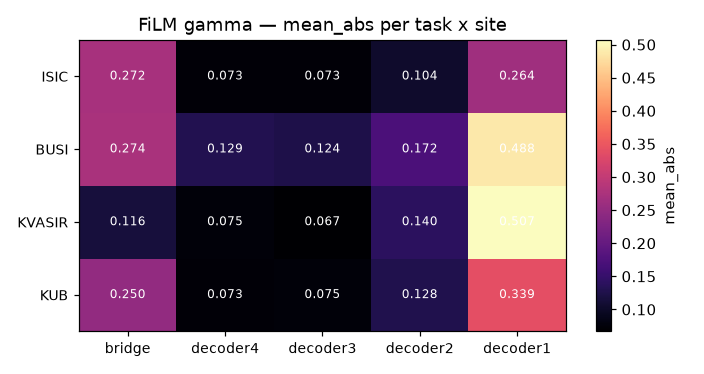

*Figure — FiLM beta mean_abs*  
`reports/figures/phase21_global_medfilm/conditioning/film_beta_mean_abs.png`

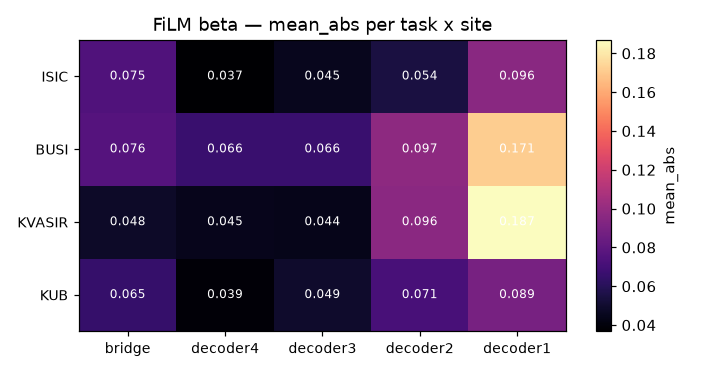

*Figure — FiLM gamma l2_norm*  
`reports/figures/phase21_global_medfilm/conditioning/film_gamma_l2_norm.png`

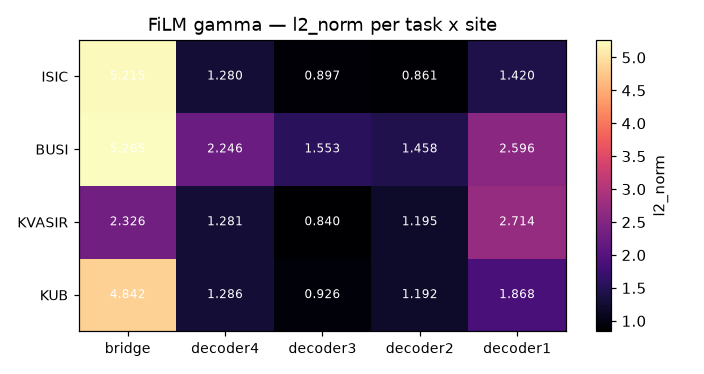

*Figure — FiLM beta l2_norm*  
`reports/figures/phase21_global_medfilm/conditioning/film_beta_l2_norm.png`

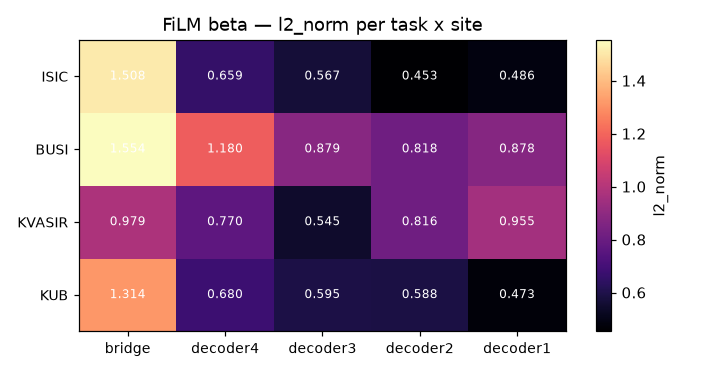

,task_id,task,film_site,parameter,n_channels,mean,std,min,max,l2_norm,mean_abs
0,0,ISIC,bridge,gamma,256,-0.000151,0.325958,-0.817907,0.693509,5.215334,0.271644
1,0,ISIC,bridge,beta,256,-0.005270,0.094091,-0.309398,0.225222,1.507821,0.074812
2,0,ISIC,decoder4,gamma,192,0.003911,0.092274,-0.246519,0.311383,1.279731,0.072641
3,0,ISIC,decoder4,beta,192,-0.012988,0.045719,-0.133340,0.089705,0.658569,0.036729
4,0,ISIC,decoder3,gamma,96,0.000640,0.091538,-0.210764,0.204056,0.896905,0.072543
5,0,ISIC,decoder3,beta,96,-0.005928,0.057527,-0.186729,0.203002,0.566635,0.045113
6,0,ISIC,decoder2,gamma,48,-0.005366,0.124120,-0.255552,0.219699,0.860729,0.103979
7,0,ISIC,decoder2,beta,48,0.000092,0.065399,-0.172764,0.112425,0.453100,0.054344
8,0,ISIC,decoder1,gamma,24,0.234650,0.170331,-0.238452,0.442240,1.420479,0.263522
9,0,ISIC,decoder1,beta,24,-0.021326,0.096965,-0.156261,0.091391,0.486384,0.095748


gamma = tanh(gamma_raw), beta = tanh(beta_raw) => |gamma|,|beta| < 1 by construction.


In [30]:
show_fig("p21_film_gamma_mean_abs")
show_fig("p21_film_beta_mean_abs")
show_fig("p21_film_gamma_l2_norm")
show_fig("p21_film_beta_l2_norm")
FS = pd.read_csv(TAB / "phase21_film_parameter_summary.csv")
display(sty(FS.head(20), "p21_fs"))
print("gamma = tanh(gamma_raw), beta = tanh(beta_raw) => |gamma|,|beta| < 1 by construction.")

## 31. Gallery — frozen 64 cases, six-model panel

,dataset,n
0,BUSI,16
1,ISIC,16
2,KUB,16
3,KVASIR,16


p21_gallery_six_* : 4 figure(s) in the frozen inventory


*Figure — Six-model gallery — BUSI*  
`reports/figures/phase21_global_medfilm/gallery/gallery_six_model_BUSI.png`

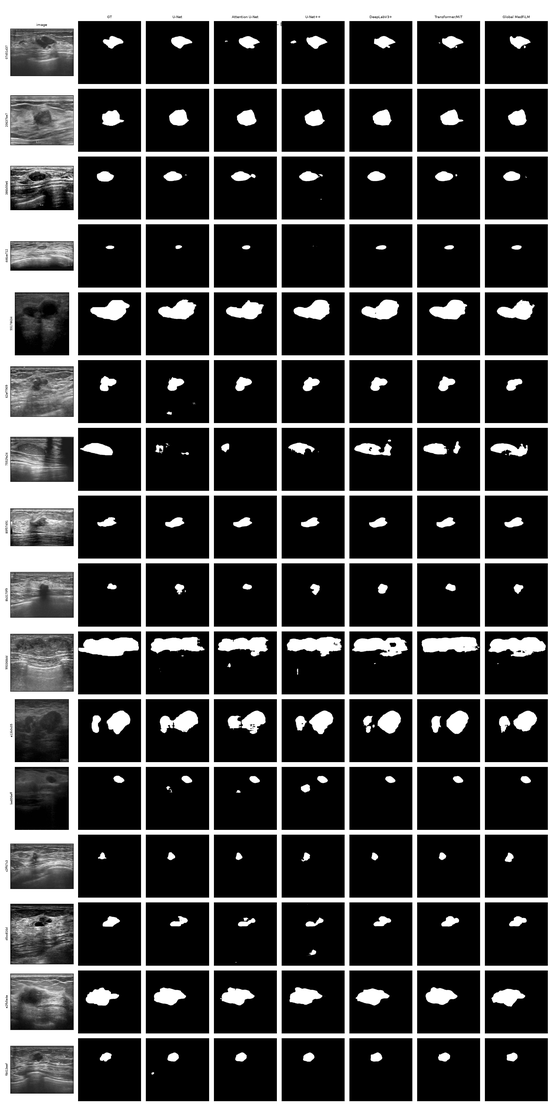

*Figure — Six-model gallery — ISIC*  
`reports/figures/phase21_global_medfilm/gallery/gallery_six_model_ISIC.png`

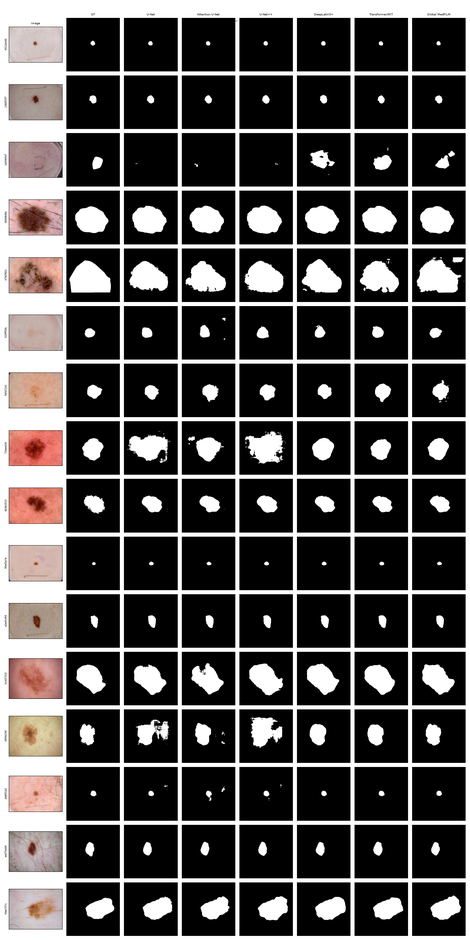

*Figure — Six-model gallery — KUB*  
`reports/figures/phase21_global_medfilm/gallery/gallery_six_model_KUB.png`

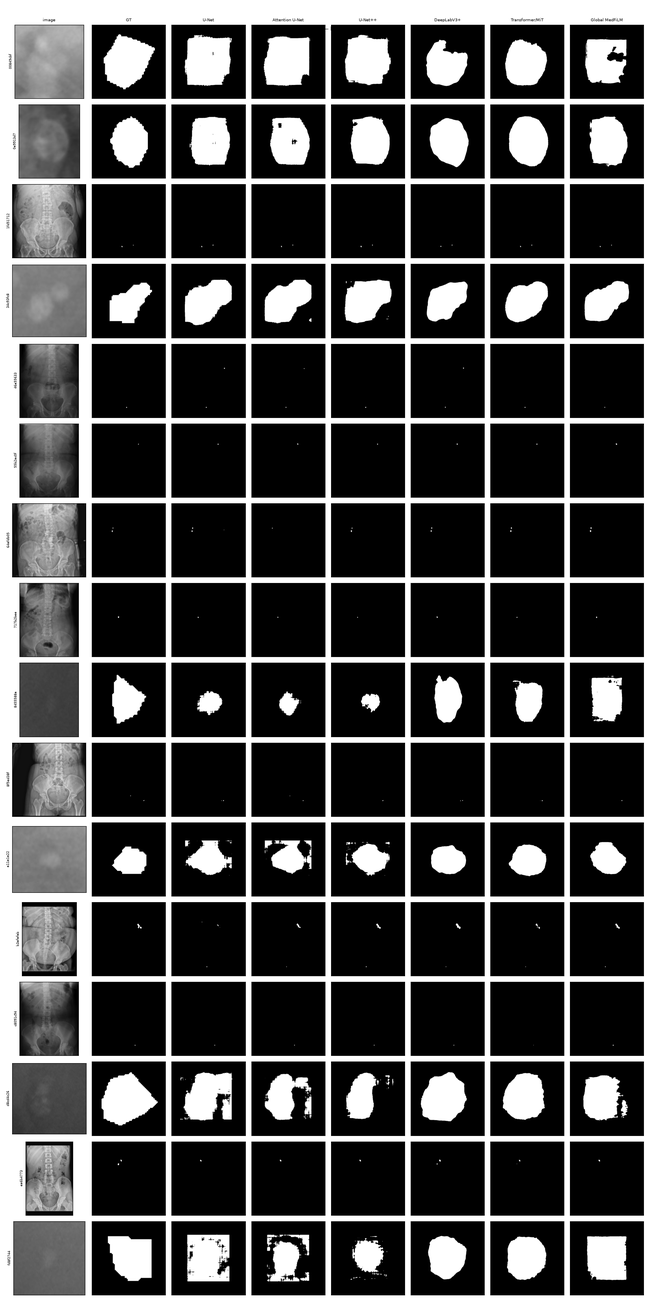

*Figure — Six-model gallery — KVASIR*  
`reports/figures/phase21_global_medfilm/gallery/gallery_six_model_KVASIR.png`

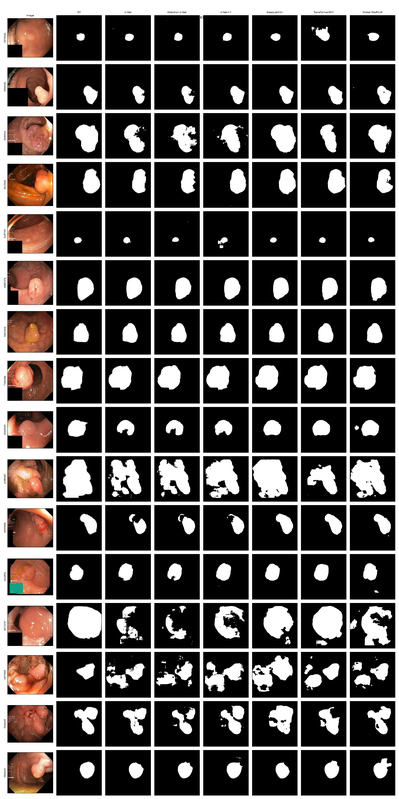

The frozen 64-case gallery (16 per domain) was reused UNCHANGED across all six models.


In [31]:
G = pd.read_csv(TAB / "phase21_gallery_selection_64.csv")
display(sty(G.groupby("dataset").size().reset_index(name="n"), "p21_g"))
show_group("p21_gallery_six_", width=1050)
print("The frozen 64-case gallery (16 per domain) was reused UNCHANGED across all six models.")

## 32. Detailed gallery (ANALYTICAL_OUTCOME_SELECTED)

p21_detailed_gallery_* : 4 figure(s) in the frozen inventory


*Figure — Detailed gallery — BUSI*  
`reports/figures/phase21_global_medfilm/gallery/detailed_gallery_BUSI.png`

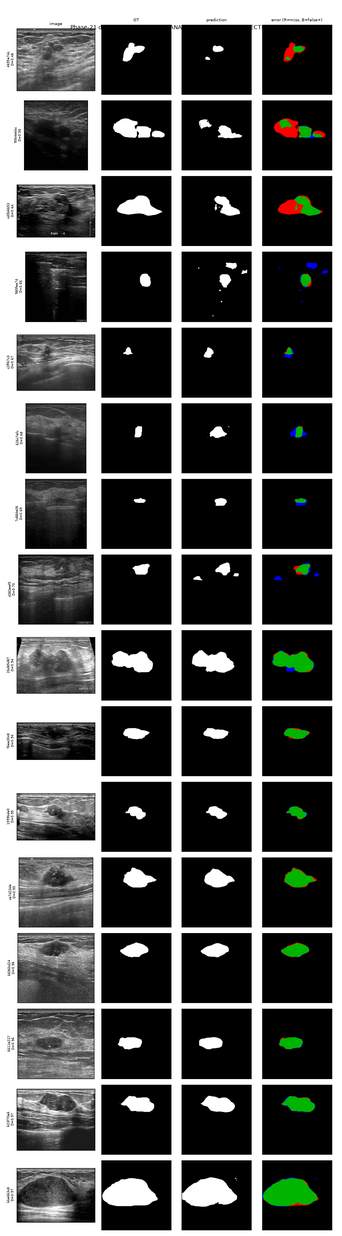

*Figure — Detailed gallery — ISIC*  
`reports/figures/phase21_global_medfilm/gallery/detailed_gallery_ISIC.png`

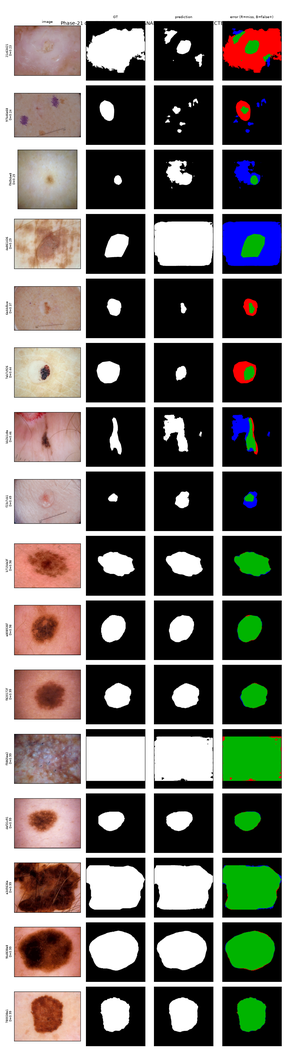

*Figure — Detailed gallery — KUB*  
`reports/figures/phase21_global_medfilm/gallery/detailed_gallery_KUB.png`

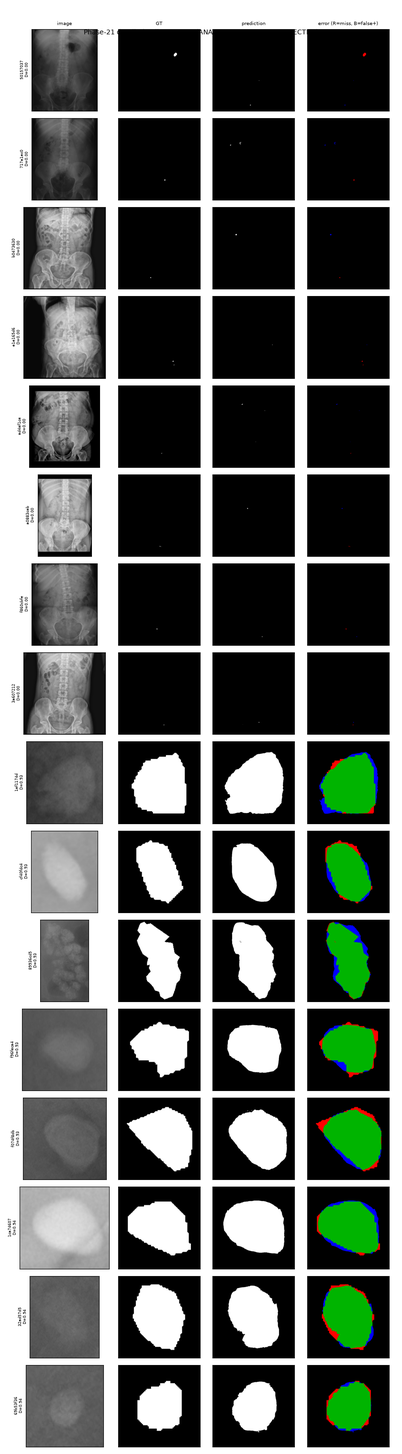

*Figure — Detailed gallery — KVASIR*  
`reports/figures/phase21_global_medfilm/gallery/detailed_gallery_KVASIR.png`

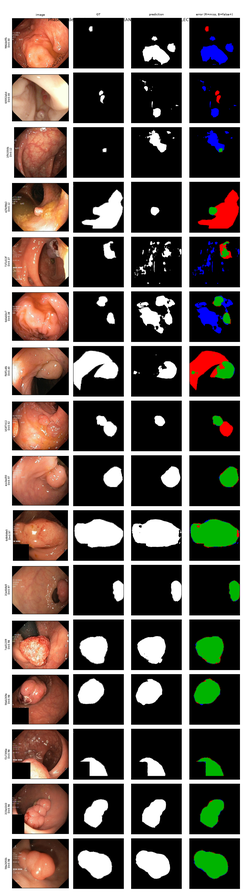

These panels are explicitly labelled ANALYTICAL_OUTCOME_SELECTED and are DISTINCT from
the fixed 64-case gallery above.


In [32]:
show_group("p21_detailed_gallery_", width=1000)
print("These panels are explicitly labelled ANALYTICAL_OUTCOME_SELECTED and are DISTINCT from")
print("the fixed 64-case gallery above.")

## 33. Failure analysis

*Figure — Worst-16 failure gallery*  
`reports/figures/phase21_global_medfilm/failure/failure_worst16.png`

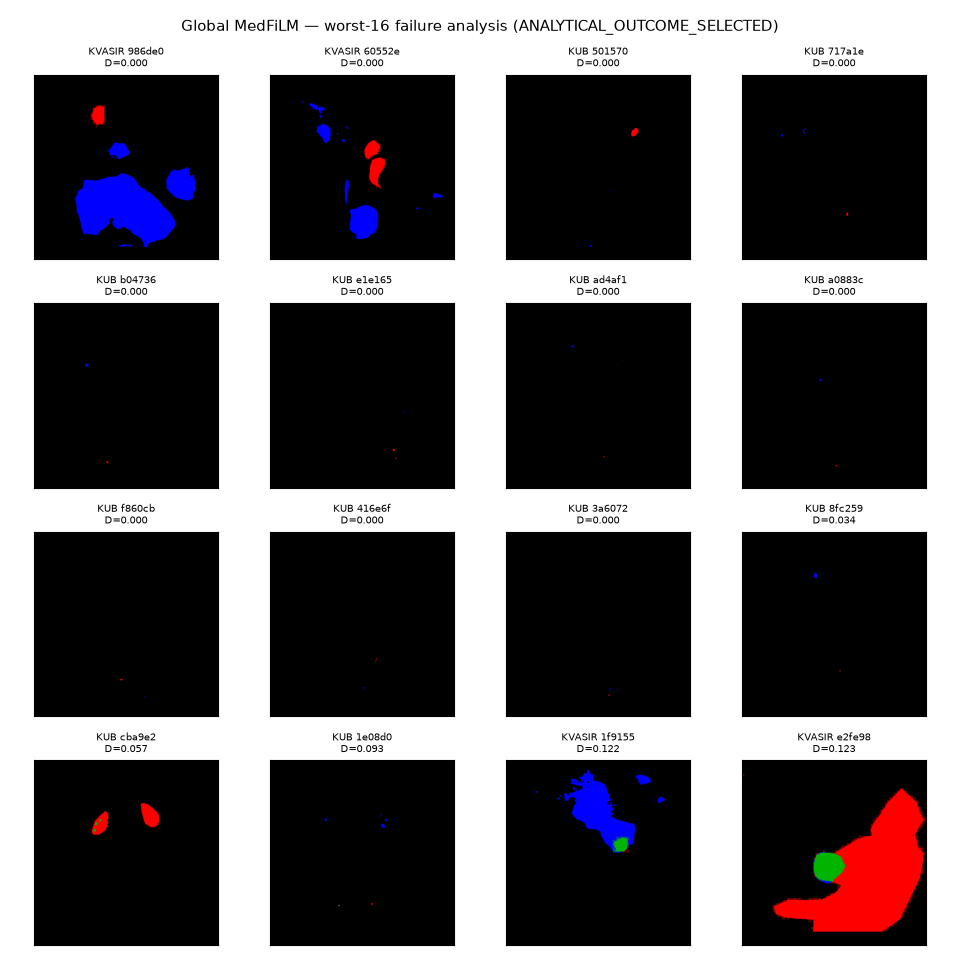

*Figure — Per-image Dice distribution*  
`reports/figures/phase21_global_medfilm/failure/dice_distribution.png`

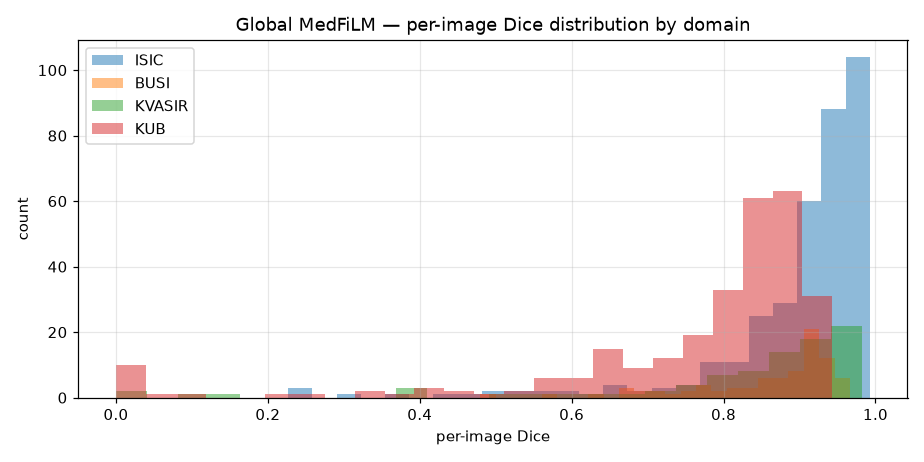

,dataset,n,mean_dice,min_dice,p10_dice,empty_pred
0,BUSI,84,0.858823,0.479650,0.716879,0
1,ISIC,357,0.897189,0.226542,0.792313,0
2,KUB,280,0.764058,0.000000,0.574907,0
3,KVASIR,87,0.820247,0.000000,0.573787,0


In [33]:
show_fig("p21_failure_worst16", width=1000)
show_fig("p21_failure_dist")
PI = pd.read_csv(TAB / "phase21_per_image_val_metrics.csv")
display(sty(PI.groupby("dataset").agg(n=("dice", "size"), mean_dice=("dice", "mean"),
                                      min_dice=("dice", "min"),
                                      p10_dice=("dice", lambda s: s.quantile(0.10)),
                                      empty_pred=("pred_empty", "sum")).reset_index(), "p21_fail"))

## 34. Parameter and compute accounting (measurement only)

efficiency figures in the frozen inventory: 3


*Figure — CPU forward latency*  
`reports/figures/phase21_global_medfilm/efficiency/cpu_latency.png`

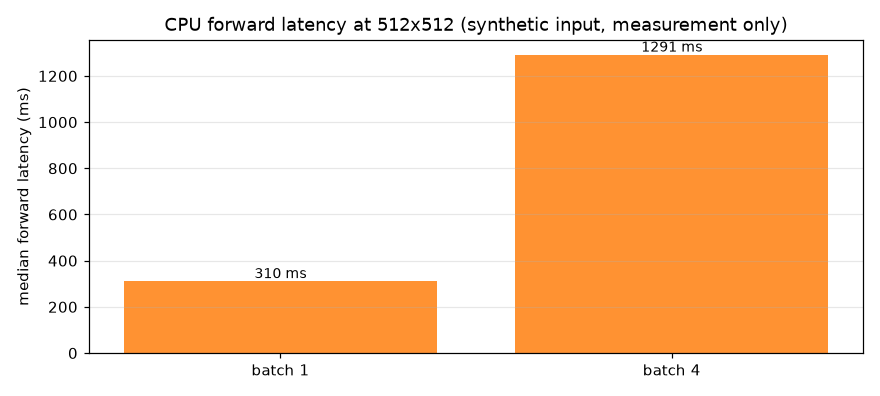

*Figure — GPU forward latency*  
`reports/figures/phase21_global_medfilm/efficiency/gpu_latency.png`

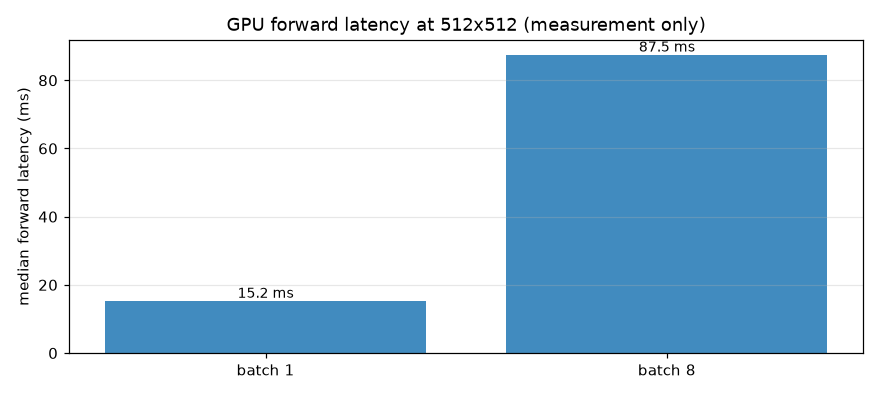

*Figure — Six-model compute comparison*  
`reports/figures/phase21_global_medfilm/efficiency/six_model_compute.png`

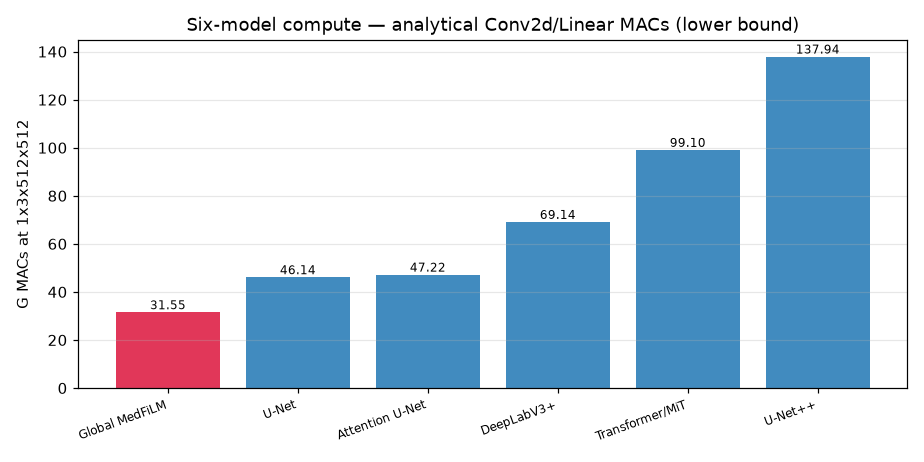

,metric,value,unit,note
0,measured_parameter_count,3523001,parameters,"trainable, measured from the frozen architecture"
1,measured_parameter_count_all,3523001,parameters,including any non-trainable parameters
2,best_checkpoint_bytes,42369710,bytes,checkpoints//best.pt
3,last_checkpoint_bytes,42369710,bytes,checkpoints//last.pt
4,best_checkpoint_sha256,286689fdd5c63ad75a383151d267af8b476e7a98327632de292ce6ed5b5ba1b7,hex,provenance
5,epochs_completed,81,epochs,from history.csv
6,mean_epoch_seconds,426.641326674074,s,all completed epochs
7,median_epoch_seconds,409.45210790000056,s,all completed epochs
8,min_epoch_seconds,379.2196243999988,s,nan
9,max_epoch_seconds,596.3692482000006,s,nan


In [34]:
# Drive EVERY efficiency figure from the frozen inventory so none can be dropped.
_eff_ids = sorted(
    fid for fid in F.figure_inventory()["figure_id"]
    if str(fid).startswith("p21_eff_"))
print(f"efficiency figures in the frozen inventory: {len(_eff_ids)}")
for _fid in _eff_ids:
    show_fig(_fid, width=900)
EF = pd.read_csv(TAB / "phase21_efficiency_accounting.csv")
display(sty(EF, "p21_ef"))

## 35. Lightweight future-design note (additive roadmap — NOT solved here)

Phase 21 does **not** solve lightweight deployment. This note is an **additive roadmap** only.

- The Global MedFiLM reference has **3,523,001** parameters and one shared head, which is
  already far smaller than the 40.3 M DeepLabV3+ baseline; parameter count is therefore not
  the binding constraint identified by this phase.
- The measured bottleneck remains **KUB tiny objects**, not model size.
- Any future lightweight work (distillation, pruning, quantization, mobile export) belongs to a
  later phase and must be evaluated under its own frozen protocol with its own controls.
- **No** compression, pruning, quantization, distillation or architecture search was performed
  in Phase 21, and none of those results are claimed here.

## 36. Figures inventory and visualization coverage

In [35]:
INV = pd.read_csv(FIG / "phase21_figure_inventory.csv")
display(sty(pd.DataFrame([
    {"item": "figures", "value": len(INV)},
    {"item": "embedded in notebook", "value": int(INV["embedded_in_notebook"].sum())},
    {"item": "groups", "value": json.dumps(INV.groupby("group").size().to_dict())},
]), "p21_inv", value="{!s}"))
display(sty(INV.groupby(["group", "category"]).size().reset_index(name="n"), "p21_inv2"))

,item,value
0,figures,43
1,embedded in notebook,43
2,groups,"{""comparison"": 17, ""conditioning"": 5, ""efficiency"": 3, ""failure"": 2, ""gallery"": 8, ""kub"": 2, ""training"": 6}"


,group,category,n
0,comparison,EFFICIENCY,1
1,comparison,PRIMARY_COMPARISON,16
2,conditioning,CONDITIONING,5
3,efficiency,EFFICIENCY,3
4,failure,FAILURE_ANALYSIS,2
5,gallery,GALLERY_DETAILED,4
6,gallery,GALLERY_FIXED_64,4
7,kub,KUB_ANALYSIS,2
8,training,TRAINING,6


## 37. Artifact index

In [36]:
# The artifact index lists the STABLE evidence this notebook summarises. The two
# self-referential finalisation artifacts are excluded by design: the notebook
# embeds phase21_final_freeze.json's own SHA/size, and the freeze records the
# notebook SHA, so including either would make the notebook permanently
# non-byte-identical across rebuilds.
SELF_REFERENTIAL = {"phase21_final_freeze.json", "phase21_notebook_determinism.json"}
rows = []
for f in sorted((AUD).glob("phase21_*.json")):
    if f.name in SELF_REFERENTIAL:
        continue
    rows.append({"artifact": f.name, "sha256": sha(f)[:16] + "...",
                 "bytes": f.stat().st_size})
display(sty(pd.DataFrame(rows), "p21_art"))
rows = []
for f in sorted((TAB).glob("phase21_*.csv")):
    rows.append({"table": f.name, "sha256": sha(f)[:16] + "...", "bytes": f.stat().st_size})
display(sty(pd.DataFrame(rows), "p21_tab"))

,artifact,sha256,bytes
0,phase21_analysis.json,24a92bc09d3bf8f1...,3429
1,phase21_analytical_mac_count.json,eb35c87f191196c6...,1954
2,phase21_efficiency_accounting.json,d48c556cf0a2e077...,3922
3,phase21_entry_gate.json,567093d222e9fc73...,4036
4,phase21_figure_file_integrity_repair.json,bd745478fdd6cc60...,19408
5,phase21_global_medfilm_architecture_binding.json,21e2c195c8da33da...,5371
6,phase21_global_medfilm_confusion_matrices.json,b9d97203c5f7c62b...,2636
7,phase21_governance_sync.json,e4fbbfe82ebba257...,805
8,phase21_legacy_medfilm_architecture_audit.json,1c68656ee29ea96e...,9371
9,phase21_notebook_visual_integrity_after_repair.json,1a2ee1131be90002...,20675


,table,sha256,bytes
0,phase21_all_trained_models_comparison.csv,ebb8efe45b77283a...,1273
1,phase21_efficiency_accounting.csv,e07d63d09313b58e...,2022
2,phase21_film_parameter_summary.csv,5ce63c95ce38f0a6...,5905
3,phase21_gallery_selection_64.csv,2bc7c16286999ced...,5481
4,phase21_global_medfilm_calibration_ranking.csv,4598617946477aae...,666
5,phase21_global_medfilm_confusion_matrices.csv,6e19e306ee21c90f...,858
6,phase21_global_medfilm_domain_bootstrap_ci.csv,4ebf24b7bfd4a682...,1106
7,phase21_global_medfilm_domain_performance.csv,7b311e2a8a1e124b...,3418
8,phase21_kub_size_stratification.csv,ed4f8a9fcf736c61...,652
9,phase21_kub_size_stratification_per_sample.csv,7bd4ab84e0acbb6a...,30071


## 38. Terminal state and Phase-22 eligibility

In [37]:
print("terminal_state   :", FREEZE.get("terminal_state"))
print("phase22_eligible :", FREEZE.get("phase22_eligible"))
print("phase22_started  :", FREEZE.get("phase22_started"))
print("freeze_verified  :", FREEZE.get("freeze_verified"))
print("validation_problems:", FREEZE.get("validation_problems"))
# The final terminal state is only asserted once the freeze is VERIFIED. During the
# bootstrap build the freeze is intentionally incomplete (the 3-build notebook
# determinism proof cannot exist yet), so asserting it here would be circular.
# Phase 22 must never be started regardless of freeze status.
assert FREEZE.get("phase22_started", False) is False
if FREEZE.get("freeze_verified") is True:
    assert FREEZE["terminal_state"] == "PHASE21_GLOBAL_MEDFILM_REFERENCE_COMPLETE__PHASE22_ELIGIBLE_NOT_STARTED"
    print()
    print("Phase 21 is COMPLETE. Phase 22 is ELIGIBLE but NOT STARTED.")
else:
    print()
    print("FREEZE NOT YET VERIFIED (status:", FREEZE.get("terminal_state"), ")")
    print("This is expected on the bootstrap build: the freeze records "
          "'notebook determinism not proven' until the 3-build proof completes.")
    print("The terminal-state assertion is re-checked on the post-freeze builds, "
          "and the freeze writer fails closed unless the state is "
          "PHASE22_ELIGIBLE_NOT_STARTED.")

terminal_state   : PHASE21_GLOBAL_MEDFILM_REFERENCE_COMPLETE__PHASE22_ELIGIBLE_NOT_STARTED
phase22_eligible : True
phase22_started  : False
freeze_verified  : True
validation_problems: []

Phase 21 is COMPLETE. Phase 22 is ELIGIBLE but NOT STARTED.


## 39. Reproduction

```bash
# 1. pre-training governance (fail-closed)
./.venv/Scripts/python.exe scripts/audits/phase21_entry_gate.py
./.venv/Scripts/python.exe scripts/audits/write_phase21_legacy_audit.py
./.venv/Scripts/python.exe scripts/audits/write_phase21_protocol_binding.py
./.venv/Scripts/python.exe scripts/audits/write_phase21_architecture_binding.py
./.venv/Scripts/python.exe scripts/audits/write_phase21_pre_execution_check.py

# 2. the ONE authorized training run (resumable; never a second logical run)
./.venv/Scripts/python.exe -u scripts/training/train_phase21_global_medfilm.py --resume

# 3. ONE canonical VAL pass
./.venv/Scripts/python.exe scripts/evaluation/evaluate_phase21_val.py

# 4. analysis / diagnostics / accounting
./.venv/Scripts/python.exe scripts/analysis/run_phase21_analysis.py
./.venv/Scripts/python.exe scripts/analysis/phase21_conditioning_diagnostic.py
./.venv/Scripts/python.exe scripts/analysis/phase21_efficiency.py

# 5. figures + freeze
./.venv/Scripts/python.exe -c "from src.analysis import phase21_figures as F; F.build_all(); F.write_inventories()"
./.venv/Scripts/python.exe scripts/analysis/write_phase21_freeze.py
```

**TEST is never read at any step.**